# WFS Workshop 2026 talk: figures

Figures of the talk "Wavefront Sensor Data Fusion for Extreme AO", following `WFS_talk_plot_spec.md`. **Nothing is simulated or
recomputed here**: the error-budget (EB) figures read the sweep cache of `analyse_errorbudget.ipynb` (`results/multiwfs_cache`,
read-only: any write raises), the E2E figures read `results/WFSW/sweep_final_20261108` and `sweep_seeing_20261110`.
The only exception is the VIS single rMod 0 baseline of case 3 (a quick leaky EB sweep from existing products, kept in memory and
flagged in the README).

- `CONTROLLER` selects the EB sweeps of one controller; a sweep that is not cached for it is skipped and listed in `MISSING_DATA.md`.
- Output: `figures/<CONTROLLER>/slideXX_<name>.{pdf,png}` (300 dpi), `README.md` and `MISSING_DATA.md` in the same folder.
- Skipped on purpose (user's decision, 2026-11-11): per-term bar charts (panel c), slide 24 (EB vs E2E), backup slides 28-39.
- The setup cell copies the settings of `analyse_errorbudget.ipynb` that enter the cache keys: if they diverge, the figures
  report missing data instead of showing other numbers.

In [ ]:
import csv
import dataclasses
import importlib.util
import os
import os.path as op
import pickle
import subprocess
import sys
import warnings

import numpy as np
import pandas as pd
import yaml
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import FancyBboxPatch, Patch
from matplotlib.ticker import FixedLocator, NullLocator, ScalarFormatter

CONTROLLER = 'leaky'          # 'leaky' or 'wiener' (EB figures); the E2E figures do not depend on it
CRITERION = 'contrast'        # EB sweeps of analyse_errorbudget.ipynb: 'contrast' (best single = best binning + rate, e2e ranking) or 'strehl'
OUT = op.abspath(op.join('figures', CONTROLLER))
os.makedirs(OUT, exist_ok=True)

E2E_DIR = op.abspath('aoeb/e2e')
sys.path.insert(0, E2E_DIR)
_spec = importlib.util.spec_from_file_location('aoeb_e2e_utils', op.join(E2E_DIR, 'utils.py'))
e2e = importlib.util.module_from_spec(_spec)
_spec.loader.exec_module(e2e)
from specula.lib.n_phot import n_phot
from aoeb.chromatic import ChromaticModel
from aoeb.psf import PsfEngine
from aoeb.multiwfs import Study
from aoeb import plotting as pl
import final_sweep_results as fr          # E2E final sweep (slide 23)
import sweep_seeing as ssee               # E2E seeing scan (slide 22)

# ---- global style of the slides
plt.rcParams.update({'text.usetex': False, 'font.family': 'STIXGeneral', 'mathtext.fontset': 'stix', 'font.size': 14, 'axes.labelsize': 16, 'xtick.labelsize': 14,
                     'ytick.labelsize': 14, 'legend.fontsize': 13, 'axes.titlesize': 15, 'figure.titlesize': 16,
                     'axes.grid': True, 'grid.alpha': 0.2, 'grid.linewidth': 0.6, 'lines.linewidth': 1.5, 'lines.markersize': 4,
                     'errorbar.capsize': 2, 'legend.frameon': False, 'image.origin': 'lower'})
FULL, HALF = (12, 4.5), (6, 4.5)
CFG = {'single': 'k', 'case1': 'C0', 'case2': 'C1', 'case3': 'C2', 'case4': 'C4', 'combined': 'C3'}   # one colour per configuration
EQ, ADD = '-', '--'                                                                                    # flux-equated / flux-added
TERM = {'lag': 'C0', 'noise_photon': 'C1', 'noise_ron': 'C5', 'alias': 'C2', 'fitting': 'C3', 'chrom_shear': 'C4', 'total': 'k'}
TERM_LABEL = {'lag': 'lag', 'noise_photon': 'noise, photon', 'noise_ron': 'noise, RON', 'alias': 'aliasing', 'fitting': 'fitting',
              'chrom_shear': 'chromatic shear', 'total': 'total'}
XLIM = (3.6, 14.4)            # same magnitude range on every EB case slide
RATIO_YLIM = (0.3, 2.0)       # same ratio range on every EB case slide (log)
RATIO_TICKS = (0.3, 0.5, 0.7, 1.0, 1.5, 2.0)
CASE_MAG_MAX = 13.0           # slides 14-16: magnitudes up to 13, no SR shading, linear ratio, lower bound (fitting [+ shear in VIS])
RATIO_YLIM_LIN = (0.4, 1.1)   # same linear ratio range on slides 14-16
CASE_KW = dict(mag_max=CASE_MAG_MAX, shade=False, linear_ratio=True)
ZONE = (2, 5)
ZONE_TXT = f'{ZONE[0]}–{ZONE[1]} $\\lambda$/D'

# ---- bookkeeping: README rows and MISSING_DATA entries
README, MISSING = [], []

def save(fig, slide, name, sources, quick_eb=None):
    stem = f'slide{slide:02d}_{name}'
    for ext in ('pdf', 'png'):
        fig.savefig(op.join(OUT, f'{stem}.{ext}'), dpi=300, bbox_inches='tight')
    README.append(dict(slide=slide, file=stem, sources=sources, quick_eb=quick_eb))
    plt.show()

def missing(slide, figure, status, what, needed, code, discrepancies='none found'):
    MISSING.append(dict(slide=slide, figure=figure, status=status, what=what, needed=needed, code=code, disc=discrepancies))

2026-11-11 16:27:28,386 [INFO]: [specula]: Cupy import successfull. Installed version is: 13.3.0
2026-11-11 16:27:28,387 [INFO]: [specula]: Default device is CPU


## Setup: the EB system and the read-only sweep cache

Copied from `analyse_errorbudget.ipynb` (cells 1 and 3): every value below enters the cache keys of `aoeb.multiwfs.Study`.

In [ ]:
YML = 'aoeb/e2e/ristretto_main.yml'
with open(YML) as f:
    Y = yaml.safe_load(f)
m = e2e.machine()
det = m.detector
m.max_sensitivity = None
SCINT, MULT, COMP = False, False, 0.0
dt = Y['main']['time_step']
zenith = Y['main']['zenithAngleInDeg']
seeing = 0.9
latency_s = Y['kpred']['delay'] * dt
N_dm = Y['dm']['nmodes']
area = (m.pupil() > 0).sum() * Y['main']['pixel_pitch'] ** 2

def sensor(name):
    pyr, ccd, src, sci = Y[f'pyr_{name}'], Y[f'cred_{name}'], Y[f'source_{name}'], Y[f'science_{name}']
    assert (ccd['readout_level'], ccd['quantum_eff'], ccd['excess_noise']) == (det.ron_e, det.qe, det.excess_noise)
    n = int(pyr['pup_diam'])
    flux = n_phot(src['magnitude'], lambda_=src['wavelengthInNm'] * 1e-9, width=1e-9)[0] * ccd['bandw'] * area
    return dict(rMod=float(pyr['mod_amp']), n_subap=n, wavelength_nm=float(pyr['wavelengthInNm']), fs=1.0 / ccd['dt'],
                N=min(N_dm, m.max_modes(n)), magnitude=src['magnitude'], flux=flux, science_nm=float(sci['wavelengthInNm']))

S = {k: sensor(k) for k in ('vis', 'nir')}
S['vis'].update(rMod=2.0, fs=2000.)
S['nir'].update(rMod=0.0, fs=2000.)
atm = Y['atmo']
chrom = {k: ChromaticModel(atm['heights'], atm['Cn2'], science_nm=s['science_nm'], zenith_deg=zenith, multiplicative=MULT,
                           compensation=COMP, fresnel=SCINT, scintillation=SCINT) for k, s in S.items()}
BANDS = {'VIS': 'vis', 'NIR': 'nir'}
MAGS = np.arange(4.0, 14.01, 1.0)
R1, RMOD_NIR = 2.0, 0.0
eng = PsfEngine(m)
st = Study(m, eng, seeing, latency_s, CONTROLLER, area, bandw=Y['cred_vis']['bandw'], colour=S['vis']['magnitude'] - S['nir']['magnitude'],
           cache_dir='results/multiwfs_cache', zone=ZONE, criterion=CRITERION)

def _read_only(*a, **k):
    raise RuntimeError('this notebook never computes or writes a cached sweep')
st.cached = st.sweep = _read_only

def set_band(name):
    global BAND, wfs_nm, sci_nm
    s = S[BANDS[name]]
    BAND, wfs_nm, sci_nm = name, s['wavelength_nm'], s['science_nm']
    st.set_band(sci_nm, dataclasses.replace(chrom[BANDS[name]], scintillation=False, fresnel=False))

def rmod(r):
    return RMOD_NIR if BAND == 'NIR' else r

def load(name, extra=(), criterion=None, controller=None):
    # cached object of Study.cached(name, ..., extra) for the current band, CONTROLLER and CRITERION (or `criterion` / `controller`), None if absent
    crit0, ctrl0 = st.criterion, st.kw['controller']
    st.criterion, st.kw['controller'] = criterion or crit0, controller or ctrl0
    try:
        p = st._key(name, tuple(extra))
    finally:
        st.criterion, st.kw['controller'] = crit0, ctrl0
    if not op.exists(p):
        return None
    with open(p, 'rb') as f:
        return pickle.load(f)

def sweep(name, mags):
    return load(name, tuple(mags))

def band_title(band):
    return f"{band} ({S[BANDS[band]]['science_nm']:.0f} nm)"

print(f'controller {CONTROLLER}, z = {zenith:g} deg, seeing {seeing}" (line of sight), {det}; figures -> {OUT}')

controller leaky, z = 30 deg, seeing 0.9" (line of sight), Detector(ron_e=0.5, qe=0.2, excess_noise=False, excess_delta=1.0); figures -> /raid1/mmenessini/git/SPECULA/config/figures/leaky


## Slides 7-8: system parameters (for the text, no figure)

In [ ]:
thr_dir = op.join(m.paths.root, 'throughput')
rows = []
for f in sorted(os.listdir(thr_dir)):
    # pyr<rMod>_<n>x<n>_wvl<wl>_s<seeing>_<N>modes_thrp.fits
    p = f[:-len('_thrp.fits')].split('_')
    if p[3] != 's0.9' and not (p[1] == '48x48' and p[4] == '1300modes'):          # 48x48: no s0.9 throughput product, every seeing listed
        continue
    from astropy.io import fits
    rows.append(dict(rMod=float(p[0][3:]), n_subap=p[1], seeing=p[3][1:], wfs_nm=int(p[2][3:]), corrected_modes=p[4], in_pupil=float(fits.getdata(op.join(thr_dir, f))[0])))
THR = pd.DataFrame(rows).sort_values(['rMod', 'n_subap', 'wfs_nm', 'seeing'])
SYS = pd.Series({
    'telescope pupil area [m^2] (SPECULA pupil)': f'{area:.2f}',
    'zenith angle z (E2E and EB chromatic model)': f'{zenith:g} deg',
    'seeing along the line of sight': f'{seeing}"',
    'EB sensor sizes': '48x48 (all cases), 14x14 / 100 modes (case 2 LO), unmodulated 14/24/36/48 (combined, sampling optimised)',
    'E2E sensor sizes (selected configs)': '48x48, 36x36, 24x24, 14x14 (see slide 23 table)',
    'WFS wavelengths': '900 nm (VIS), 1300 nm (NIR); case 4: 750 / 950 nm',
    'science wavelengths': '550 nm (VIS), 1650 nm (NIR)',
    'camera band per WFS': f"{Y['cred_vis']['bandw']} nm",
    'global throughput (QE x transmission)': f'{det.qe:g}',
    'readout noise': f'{det.ron_e:g} e- rms, no excess noise',
    'in-pupil fraction, unmodulated': f"{THR[THR.rMod == 0].in_pupil.min():.2f}-{THR[THR.rMod == 0].in_pupil.max():.2f} (table below)",
    'in-pupil fraction, rMod 2': f"{THR[THR.rMod == 2].in_pupil.min():.2f}-{THR[THR.rMod == 2].in_pupil.max():.2f} (table below)",
    'magnitude reference': 'magnitude at 900 nm; 1300 nm star = m900 - '
                           f"{S['vis']['magnitude'] - S['nir']['magnitude']:.2f} (colour of the yml sources)",
    'spectrum assumption': 'photons/s/nm of an A0 star of that magnitude at the band centre (n_phot, nearest Johnson band zero point), '
                           'flat over the 400 nm band; case 4 bands take their share of the 900 nm band photons',
    'photons/s on the pupil for m900 = 0, 900 / 1300 nm band (before QE)': f"{st.flux_of(0.0, 900.):.3e} / {st.flux_of(0.0, 1300.):.3e}",
})
display(SYS.to_frame('value'))
THR

,value
telescope pupil area [m^2] (SPECULA pupil),51.00
zenith angle z (E2E and EB chromatic model),30 deg
seeing along the line of sight,"0.9"""
EB sensor sizes,"48x48 (all cases), 14x14 / 100 modes (case 2 L..."
E2E sensor sizes (selected configs),"48x48, 36x36, 24x24, 14x14 (see slide 23 table)"
WFS wavelengths,"900 nm (VIS), 1300 nm (NIR); case 4: 750 / 950 nm"
science wavelengths,"550 nm (VIS), 1650 nm (NIR)"
camera band per WFS,400 nm
global throughput (QE x transmission),0.2
readout noise,"0.5 e- rms, no excess noise"


,rMod,n_subap,seeing,wfs_nm,corrected_modes,in_pupil
1,0.0,14x14,0.9,900,1300modes,0.630404
0,0.0,14x14,0.9,1300,1300modes,0.595194
3,0.0,24x24,0.9,900,1300modes,0.617893
2,0.0,24x24,0.9,1300,1300modes,0.580520
6,0.0,36x36,0.9,900,1300modes,0.594127
7,0.0,36x36,0.9,900,900modes,0.617168
4,0.0,36x36,0.9,1300,1300modes,0.555464
5,0.0,36x36,0.9,1300,900modes,0.568048
11,0.0,48x48,0.6,900,1300modes,0.555316
12,0.0,48x48,0.75,900,1300modes,0.567533


## Slide 12: EB pipeline example (NIR, 1300 nm, rMod 0, mag 5)

Three figures: PSD by term, 2-D PSF without coronagraph (total) and radial contrast by term, of the single-stage budget of `analyse_errorbudget.ipynb` (cached `BudgetResult`; PSD and
PSF are computed from it as in that notebook, no new budget).

Cupy import successfull. Installed version is: 13.3.0


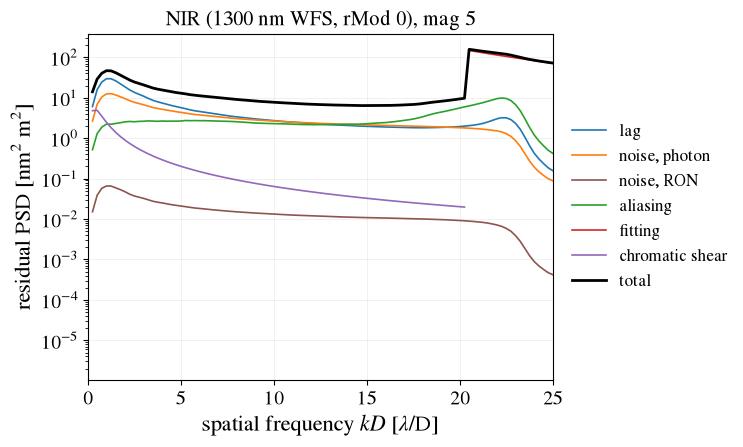

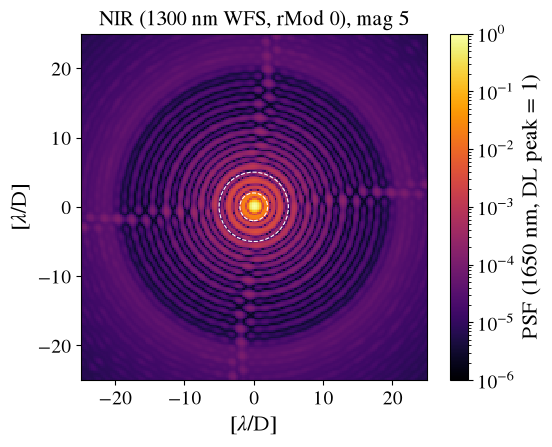

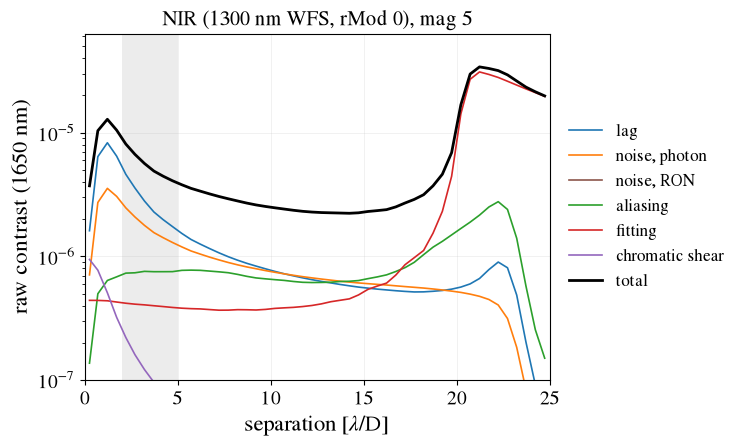

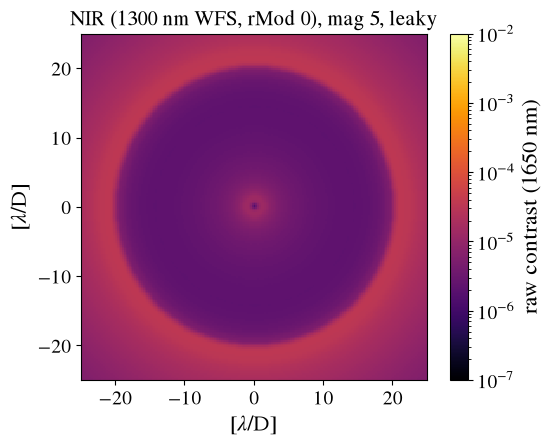

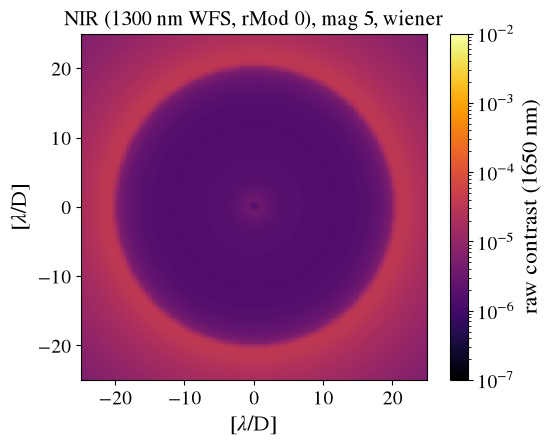

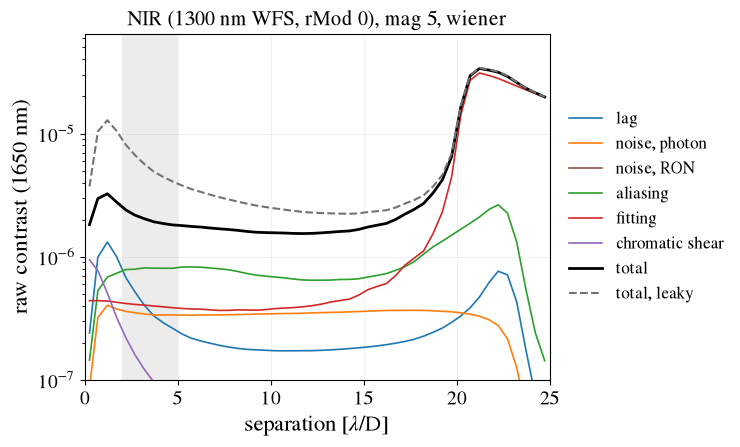

In [ ]:
MAG_FIRST = {'high flux': 5.0, 'low flux': 11.0}
def single_stage(lab, k, controller=None):
    s = S[k]
    set_band('VIS')          # analyse_errorbudget.ipynb caches all four under the VIS band settings (set_band('VIS') ends its cell 3)
    name, extra = f'single-stage {lab} {k} rMod{s["rMod"]:g} fs{s["fs"]:g}', (MAG_FIRST[lab], SCINT, MULT, COMP)
    return (load(name, extra, controller=controller) or
            load(name, extra, criterion='strehl', controller=controller))    # fixed configuration: the same under both criteria

def stage_title(k, mg):
    s = S[k]
    return (f"{k.upper()}: {s['n_subap']}x{s['n_subap']}, {s['wavelength_nm']:.0f} nm, rMod {s['rMod']:g}, {s['fs'] / 1e3:g} kHz, "
            f"z = {zenith:g}°, mag {mg:g}")

def coro_terms(ax, res, rmax=25):
    for n, c in TERM.items():
        if n in res.coro:
            r, p = res.profile(n, 'coro', 0.5, 'mean', rmax)
            ax.semilogy(r, p, color=c, lw=2.0 if n == 'total' else 1.2, label=TERM_LABEL[n])
    ax.axvspan(*ZONE, color='gray', alpha=0.15, lw=0)
    ax.set_xlabel('separation [$\\lambda$/D]')
    ax.set_xlim(0, rmax)

K12 = 'nir'                       # band of the example: NIR pyramid, rMod 0
r12 = single_stage('high flux', K12)
if r12 is None:
    missing(12, 'EB pipeline example', 'not produced', f'single-stage {K12.upper()} budget, mag 5, {CONTROLLER}', 'analyse_errorbudget.ipynb cell 4',
            'ErrorBudgetMachine.budget')
else:
    psd = eng.psd_terms(r12)
    res = eng.psf_terms(r12, S[K12]['science_nm'])
    src12 = f'results/multiwfs_cache: single-stage high flux {K12} ({CONTROLLER}); PsfEngine.psd_terms / psf_terms'
    title12 = f"{K12.upper()} ({S[K12]['wavelength_nm']:.0f} nm WFS, rMod {S[K12]['rMod']:g}), mag 5"
    leg_right = lambda ax: ax.legend(loc='center left', bbox_to_anchor=(1.01, 0.5), fontsize=12)
    # (a) PSD of every term
    fig, a = plt.subplots(figsize=HALF)
    for n, c in TERM.items():
        if n in psd.terms:
            t = psd.terms[n]
            ok = (psd.k > 0) & (t.psd > 0)
            a.semilogy(psd.k[ok] * psd.D, t.psd[ok], color=c, lw=2.0 if n == 'total' else 1.2, label=TERM_LABEL[n])
    a.set_xlim(0, 25)
    a.set(xlabel='spatial frequency $k D$ [$\\lambda$/D]', ylabel='residual PSD [nm$^2$ m$^2$]', title=title12)
    leg_right(a)
    save(fig, 12, f'eb_psd_{K12.upper()}_mag5_' + CONTROLLER, src12)
    # (b) 2-D PSF (total, no coronagraph, diffraction-limited peak = 1), log scale 1e-7 .. 1e-2
    img = res.image('total', 'psf')
    ny, nx = img.shape
    ext = np.array([-(nx // 2), nx - nx // 2, -(ny // 2), ny - ny // 2]) * res.pixel_scale
    fig, a = plt.subplots(figsize=HALF)
    im = a.imshow(np.maximum(img, 1e-12), norm=mpl.colors.LogNorm(1e-6, 1), cmap='inferno', extent=ext, interpolation='nearest')
    # for rz in ZONE:
    #     a.add_patch(plt.Circle((0, 0), rz, fill=False, color='w', lw=0.8, ls='--'))
    a.set(xlim=(-25, 25), ylim=(-25, 25), xlabel='[$\\lambda$/D]', ylabel='[$\\lambda$/D]', title=title12, aspect='equal')
    a.grid(False)
    fig.colorbar(im, ax=a, label=f"PSF ({S[K12]['science_nm']:.0f} nm, DL peak = 1)")
    save(fig, 12, f'eb_psf2d_{K12.upper()}_mag5_' + CONTROLLER, src12 + '; image total, psf (no coronagraph, DL peak = 1); dashed circles: 2 and 5 lambda/D')
    # (c) radial profile of every term
    fig, b = plt.subplots(figsize=HALF)
    coro_terms(b, res)
    b.set(ylim=(1e-7, None), ylabel=f"raw contrast ({S[K12]['science_nm']:.0f} nm)", title=title12)
    leg_right(b)
    save(fig, 12, f'eb_contrast_profile_{K12.upper()}_mag5_' + CONTROLLER, src12 + '; azimuthal mean, perfect coronagraph')
    # (d) 2-D PSF after a perfect coronagraph (Cavarroc et al. 2006: coherent part removed), same scale as (b)
    def coro2d(rr, ctrl):
        img = rr.image('total', 'coro')
        ny, nx = img.shape
        ext = np.array([-(nx // 2), nx - nx // 2, -(ny // 2), ny - ny // 2]) * rr.pixel_scale
        fig, a = plt.subplots(figsize=HALF)
        im = a.imshow(np.maximum(img, 1e-12), norm=mpl.colors.LogNorm(1e-7, 1e-2), cmap='inferno', extent=ext, interpolation='nearest')
        # for rz in ZONE:
        #     a.add_patch(plt.Circle((0, 0), rz, fill=False, color='w', lw=0.8, ls='--'))
        a.set(xlim=(-25, 25), ylim=(-25, 25), xlabel='[$\\lambda$/D]', ylabel='[$\\lambda$/D]', title=f'{title12}, {ctrl}', aspect='equal')
        a.grid(False)
        fig.colorbar(im, ax=a, label=f"raw contrast ({S[K12]['science_nm']:.0f} nm)")   # perfect-coronagraph PSF / DL peak
        save(fig, 12, f'eb_coro2d_{K12.upper()}_mag5_' + ctrl, f'results/multiwfs_cache: single-stage high flux {K12} ({ctrl}); PsfEngine.psf_terms; '
             'image total, coro (perfect coronagraph, Cavarroc et al. 2006); dashed circles: 2 and 5 lambda/D')
    coro2d(res, CONTROLLER)
    # (e, f) the other controller: same budget (same sensor, rate, modes, magnitude), coronagraphic PSF and contrast profile
    OTHER = 'wiener' if CONTROLLER == 'leaky' else 'leaky'
    r12o = single_stage('high flux', K12, controller=OTHER)
    if r12o is None:
        missing(12, f'EB pipeline example, {OTHER}', 'not produced', f'single-stage {K12.upper()} budget, mag 5, {OTHER}',
                'analyse_errorbudget.ipynb cell 4 with CONTROLLER = ' + repr(OTHER), 'ErrorBudgetMachine.budget')
    else:
        reso = eng.psf_terms(r12o, S[K12]['science_nm'])
        coro2d(reso, OTHER)
        fig, b = plt.subplots(figsize=HALF)
        coro_terms(b, reso)
        rr, p = res.profile('total', 'coro', 0.5, 'mean', 25)
        b.semilogy(rr, p, color='0.45', lw=1.5, ls='--', label=f'total, {CONTROLLER}')
        b.set(ylim=(1e-7, None), ylabel=f"raw contrast ({S[K12]['science_nm']:.0f} nm)", title=f'{title12}, {OTHER}')
        leg_right(b)
        save(fig, 12, f'eb_contrast_profile_{K12.upper()}_mag5_{OTHER}_vs_{CONTROLLER}',
             f'results/multiwfs_cache: single-stage high flux {K12} ({OTHER} terms; dashed: total of {CONTROLLER}); azimuthal mean, perfect coronagraph')

## Slide 13: what limits the contrast (550 / 1650 nm x mag 5 / 11)

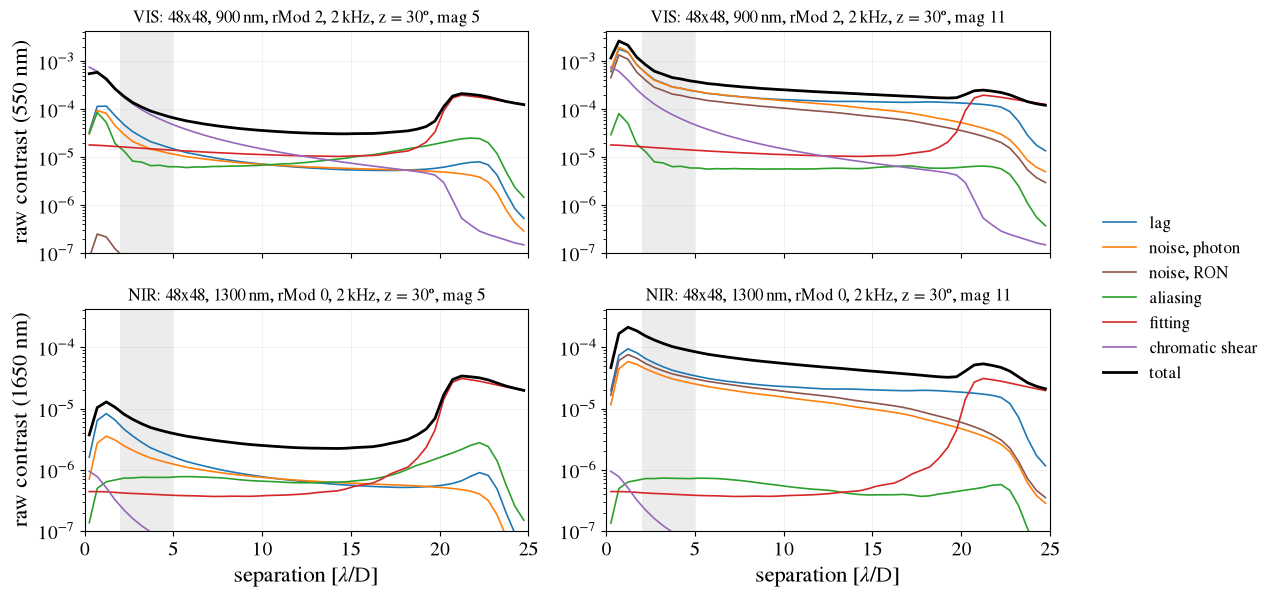

In [ ]:
fig, axs = plt.subplots(2, 2, figsize=(13, 6.2), sharex=True)
ok13 = True
for i, k in enumerate(('vis', 'nir')):
    lo, hi = np.inf, 0.0
    for j, lab in enumerate(MAG_FIRST):
        r = single_stage(lab, k)
        ax = axs[i, j]
        if r is None:
            ok13 = False
            ax.set_axis_off()
            continue
        res = eng.psf_terms(r, S[k]['science_nm'])
        coro_terms(ax, res)
        rr, p = res.profile('total', 'coro', 0.5, 'mean', 25)
        for n in TERM:
            if n in res.coro:
                q = res.profile(n, 'coro', 0.5, 'mean', 25)[1][rr >= 1]
                hi = max(hi, np.nanmax(q))
        ax.set_title(stage_title(k, MAG_FIRST[lab]), fontsize=12)
        if j == 0:
            ax.set_ylabel(f"raw contrast ({S[k]['science_nm']:.0f} nm)")
        if i == 0:
            ax.set_xlabel('')
    for ax in axs[i]:
        ax.set_ylim(1e-7, 2 * hi)                                  # identical y range in a row
h, l = axs[0, 0].get_legend_handles_labels()
fig.tight_layout(rect=(0, 0, 0.84, 1))
fig.legend(h, l, loc='center left', bbox_to_anchor=(0.845, 0.5), ncol=1, fontsize=12)
if ok13:
    save(fig, 13, 'contrast_terms_grid_' + CONTROLLER, f'results/multiwfs_cache: single-stage high/low flux vis/nir ({CONTROLLER})')
else:
    plt.close(fig)
    missing(13, 'contrast-limit grid', 'not produced', f'single-stage budgets ({CONTROLLER})', 'analyse_errorbudget.ipynb cell 4', 'ErrorBudgetMachine.budget')

## Standard EB case figure

(a) raw contrast (2-5 λ/D, perfect coronagraph) vs magnitude, with the lower bound of the 48x48 (NIR: fitting term alone; VIS:
fitting + chromatic shear, sensing at 900 nm, computed together as one residual), from the cached single-stage budget: same modes, seeing and chromatic model as every
fused sweep, checked; (b) fused / single ratio, same y range on every case
slide. Slides 14-16: magnitudes up to 13, linear ratio axis, no shading (`CASE_KW`); case 4 keeps the shading (science SR of the
single-sensor reference below 0.25) and the log ratio axis. Panel (c) (per-term bars) is not produced (decision).

In [ ]:
from collections import OrderedDict

def _sr_shade(ax, df):
    bad = df.index[df['SR'] < st.sr_min]
    for mg in bad:
        ax.axvspan(mg - 0.5, mg + 0.5, color='gray', alpha=0.15, lw=0)

def fitting_limit(band):
    # lower bound of the 48x48 (2-5 lambda/D, perfect coronagraph) from the cached single-stage budget of the band: the fitting term,
    # plus in VIS the chromatic shear (900 nm WFS, 550 nm science). Both are the same in every fused sweep (same modes, seeing, WFS
    # wavelength and chromatic model: checked against the sweeps' 'fitting' and 'chrom_shear' columns by the caller)
    # -> (contrast, fitting nm, chromatic shear nm or None, label)
    r = single_stage('high flux', band.lower())
    set_band(band)                                   # single_stage switches to the VIS settings
    if r is None:
        return None, None, None, None
    v = r.variances()
    terms = ('fitting', 'chrom_shear') if band == 'VIS' else ('fitting',)
    c = joint_contrast(r, terms)
    if band == 'VIS':
        return c, float(np.sqrt(v['fitting'])), float(np.sqrt(v['chrom_shear'])), 'fitting + chromatic shear (48x48, 1300 modes)'
    return c, float(np.sqrt(v['fitting'])), None, 'fitting limit (48x48, 1300 modes)'

def joint_contrast(r, terms):
    # zone contrast of the PSD terms `terms` TOGETHER (one residual: their covariances summed, as the total of PsfModel.psfs). Not the
    # sum of the terms' own contrasts: each term alone is a near-perfect wavefront whose coronagraphic halo the other errors do not
    # attenuate (VIS mag 5: the terms alone sum to 1.5x the total). Check: all the components together give the budget's contrast.
    psd = eng.psd_terms(r)
    zone = list(np.arange(ZONE[0], ZONE[1] + 1e-9))
    eng.psf_terms(r, st.sci_nm, names=[])                    # builds the PSF model
    def c(names):
        sub = dataclasses.replace(psd, terms=OrderedDict((n, psd.terms[n]) for n in names))
        return float(np.mean(eng._model.psfs(sub, st.sci_nm, names=[], open_loop=False).contrast_at(zone, name='total', kind='coro')))
    comps = [n for n in psd.terms if n not in ('total', 'turbulence', 'noise')]
    assert abs(c(comps) / st.contrast(r) - 1) < 1e-6
    return c(terms)

def case_figure(curves, ref, title, mag_max=None, fit=None, shade=True, linear_ratio=False):
    # curves: [(label, sweep DataFrame, colour, linestyle, marker)]; ref: label of the single-sensor reference
    # mag_max: last magnitude shown; fit: fitting_limit(band), checked against the curves' 'fitting' (and 'chrom_shear') columns
    if mag_max is not None:
        curves = [(lab, df[df.index <= mag_max + 1e-9], *rest) for lab, df, *rest in curves]
    d = {c[0]: c[1] for c in curves}
    fig, (a, b) = plt.subplots(1, 2, figsize=FULL)
    if shade:
        for ax in (a, b):
            _sr_shade(ax, d[ref])
    if fit is not None and fit[0] is not None:
        for lab, df, *_ in curves:            # the fused systems keep the 48x48 (1300 modes); a best single may be binned
            if not lab.startswith('best single'):
                assert np.allclose(df['fitting'], fit[1], rtol=1e-6), (lab, df['fitting'].unique(), fit[1])
                if fit[2] is not None:
                    assert np.allclose(df['chrom_shear'], fit[2], rtol=1e-6), (lab, df['chrom_shear'].unique(), fit[2])
        a.axhline(fit[0], color='k', ls=':', lw=1.2, label=fit[3])
    singles = [c for c in curves if c[0].startswith('best single') and 'n_subap' in c[1]]
    for j, (lab, df, col, *_) in enumerate(singles):    # binning of a best single where it is not 48x48 (a second one: below)
        for mg, n, c in zip(df.index, df['n_subap'], df['contrast']):
            if np.isfinite(n) and n != 48:
                a.annotate(f'{n:.0f}', (mg, c), xytext=(0, 6 if j == 0 else -7), textcoords='offset points', ha='center',
                           va='bottom' if j == 0 else 'top', fontsize=9, color=col)
    for lab, df, col, ls, mk in curves:
        a.semilogy(df.index, df['contrast'], ls=ls, color=col, marker=mk, ms=4, label=lab)
        if lab != ref:
            b.plot(df.index, df['contrast'] / d[ref]['contrast'].reindex(df.index), ls=ls, color=col, marker=mk, ms=4)
    b.axhline(1.0, color='gray', lw=1)
    if linear_ratio:
        b.set_ylim(*RATIO_YLIM_LIN)
    else:
        b.set_yscale('log'); b.set_ylim(*RATIO_YLIM)
        b.yaxis.set_major_locator(FixedLocator(RATIO_TICKS)); b.yaxis.set_minor_locator(NullLocator())
        b.yaxis.set_major_formatter(ScalarFormatter())
    b.text(*((0.02, 0.04, 'lower is better') if linear_ratio else (0.98, 0.04, 'lower is better')), transform=b.transAxes,
           ha='left' if linear_ratio else 'right', va='bottom', fontsize=13, color='0.3')
    a.set_ylabel(f'raw contrast {ZONE_TXT} ({sci_nm:.0f} nm)')
    b.set_ylabel('contrast: fused / single')
    for ax in (a, b):
        ax.set_xlabel('magnitude at 900 nm')
        ax.set_xlim(*(XLIM if mag_max is None else (XLIM[0], mag_max + 0.4)))
    h, l = a.get_legend_handles_labels()
    if shade:
        h.append(Patch(color='gray', alpha=0.15)); l.append(f'single: science SR $<$ {st.sr_min:g}')
    title = 'numbers: binning of the best single where not 48x48' if any(c[0].startswith('best single') for c in curves) else None
    fig.legend(h, l, title=title, fontsize=12, title_fontsize=12, loc='lower center', ncol=2, frameon=False)
    fig.tight_layout(rect=(0, 0.06 * (1 + (len(l) + 1) // 2), 1, 1))
    return fig

In [ ]:
# ---- radial contrast profile, best single vs each fusion, at the magnitude of the lowest contrast ratio (fused / single)
# The sweeps hold one row per magnitude (no PSF). Each budget is rebuilt with the call of Study that made it, at the configuration of
# its row (binning, frame rates, flux split), and must reproduce the cached contrast to 1e-6 (else the panel is listed as missing).
# Rebuilt budgets are kept in figures/<CONTROLLER>/profile_cache, never in the EB cache.
PROFILE_CACHE = op.join(OUT, 'profile_cache')

def rebuilt(name, mg, row, make):
    os.makedirs(PROFILE_CACHE, exist_ok=True)
    p = op.join(PROFILE_CACHE, op.basename(st._key(f'talk profile {name}', (mg, tuple(np.round(row.to_numpy(dtype=float), 9))))))
    if op.exists(p):
        with open(p, 'rb') as f:
            return pickle.load(f)
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        r = make(mg, row)
    with open(p, 'wb') as f:
        pickle.dump(r, f)
    return r

def rb_single(rMod, wl, chromatic=True):
    # Study.best_contrast_single / single / best_single at the row's binning, rate and modes
    return lambda mg, row: m.budget(rMod, int(row['n_subap']), seeing, st.flux_of(mg, wl), float(row['fs']), N=int(row['N']),
                                    wavelength_nm=wl, chromatic=st._chrom(chromatic), warn=False, **st.kw)

def rb_fused(sensors):
    # Study.fused at the row's rate; sensors(mg) -> sensor dicts
    return lambda mg, row: m.budget_fused([{k: v for k, v in s.items() if k != 'fs'} for s in sensors(mg)], seeing, float(row['fs']),
                                          chromatic=st.chromatic, warn=False, **st.kw)

def rb_dual(lo, ho, chromatic=True):
    # Study.best_dual / best_split at the row's HO and LO rates; lo(mg, row), ho(mg, row) -> sensor dicts
    def make(mg, row):
        h = {**ho(mg, row), 'fs': float(row['fs'])}
        return m.budget_dual({**lo(mg, row), 'fs': float(row['fs_lo'])}, h, seeing, latency_s=st.kw['latency_s'],
                             controller=st.kw['controller'], chromatic=st._chrom(chromatic), r_ho=st.stage(h, h['fs']))
    return make

def _config(row, single):
    rate = f"{row['fs']:.0f} Hz" if not np.isfinite(row.get('fs_lo', np.nan)) else f"HO {row['fs']:.0f} Hz, LO {row['fs_lo']:.0f} Hz"
    return f"{int(row['n_subap'])}x{int(row['n_subap'])}, {rate}" if single else rate

def profile_figure(slide, name, title, ref, fusions, one_panel=False):
    # ref: (label, sweep, rebuild); fusions: [(label, sweep, rebuild, colour, linestyle)]. One panel per fusion, at the magnitude
    # (<= CASE_MAG_MAX) of its lowest contrast ratio to ref; one_panel: all fusions in one panel, at the magnitude of the lowest ratio
    # among them (each fusion's ratio at that magnitude in its legend entry)
    lab0, d0, make0 = ref
    ratios = {}
    for lab, d, *_ in fusions:
        q = (d['contrast'] / d0['contrast']).dropna()
        ratios[lab] = q[q.index <= CASE_MAG_MAX + 1e-9]
    fusions = [f for f in fusions if not ratios[f[0]].empty]
    if not fusions:
        return
    if one_panel:
        mg = float(min((ratios[f[0]] for f in fusions), key=lambda q: q.min()).idxmin())
        groups = [(mg, [f for f in fusions if mg in ratios[f[0]].index])]
    else:
        groups = [(float(ratios[f[0]].idxmin()), [f]) for f in fusions]

    def get(nm, dd, mk, mg):
        row = dd.loc[mg]
        r = rebuilt(f'{name} {nm}', mg, row, mk)
        dev = abs(st.contrast(r) / row['contrast'] - 1)
        if not dev < 1e-6:
            missing(slide, f'{title}: profile of "{nm}" at mag {mg:g}', 'not produced', f'rebuilt budget differs from the sweep row '
                    f'(contrast {dev:.1e} relative)', 'a budget of the exact configuration of the row', 'Study / ErrorBudgetMachine')
            return None
        return r, row

    panels = []
    for mg, fs in groups:
        r0 = get(lab0, d0, make0, mg)
        lines = [(f'{lab0}\n({_config(r0[1], True)})', CFG['single'], '-', r0)] if r0 else []
        for lab, d, make, col, ls in fs:
            rr = get(lab, d, make, mg)
            if rr:
                txt = f', ratio {ratios[lab][mg]:.2f}' if one_panel else ''
                lines.append((f'{lab}\n({_config(rr[1], False)}{txt})', col, ls, rr))
        if r0 and len(lines) > 1:
            head = f'mag {mg:g}' if one_panel else f'mag {mg:g}: contrast ratio {ratios[fs[0][0]][mg]:.2f}'
            panels.append((head, lines))
    if not panels:
        return
    fig, axs = plt.subplots(1, len(panels), figsize=(HALF[0] * len(panels), 4.6), sharey=True, squeeze=False, layout='constrained')
    lo = np.inf
    for a, (head, lines) in zip(axs[0], panels):
        for lb, c, s, (r, row) in lines:
            x, p = eng.psf_terms(r, st.sci_nm, names=['total']).profile('total', 'coro', 0.5, 'mean', 25)
            a.semilogy(x, p, color=c, ls=s, label=lb)
            lo = min(lo, float(np.min(p[x >= 1])))
        a.axvspan(*ZONE, color='gray', alpha=0.15, lw=0)
        a.set(xlim=(0, 25), xlabel='separation [$\\lambda$/D]', title=head)
        a.legend(fontsize=10, loc='upper center', bbox_to_anchor=(0.5, -0.24), ncol=1)
        a.yaxis.set_minor_locator(mpl.ticker.LogLocator(subs=(2, 5)))        # labels at 1, 2, 5 per decade only
        a.yaxis.set_minor_formatter(mpl.ticker.LogFormatterSciNotation(labelOnlyBase=False))
    axs[0, 0].set(ylim=(0.5 * lo, None), ylabel=f'raw contrast ({st.sci_nm:.0f} nm)')
    fig.suptitle(title, fontsize=13)
    save(fig, slide, name, f'{title}: budgets rebuilt from the sweep rows (contrast reproduced to 1e-6); PsfEngine.psf_terms, perfect '
         'coronagraph, azimuthal mean', quick_eb='budgets of the cached configurations (sweep rows), rebuilt for the PSF: not in the EB cache')

## Slide 14: case 1, double flux (a second identical 48x48)

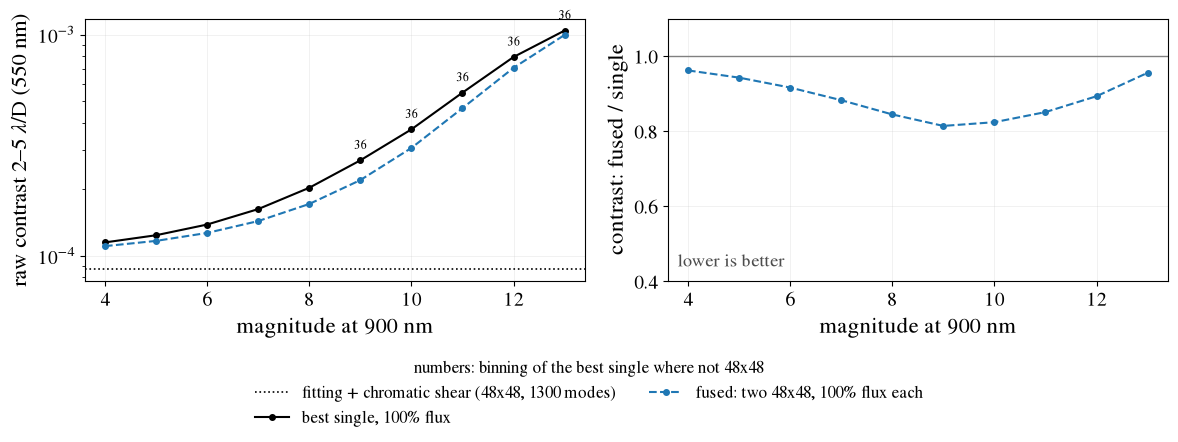

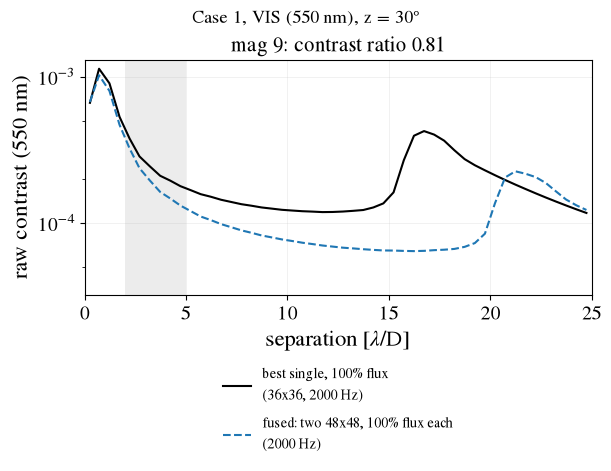

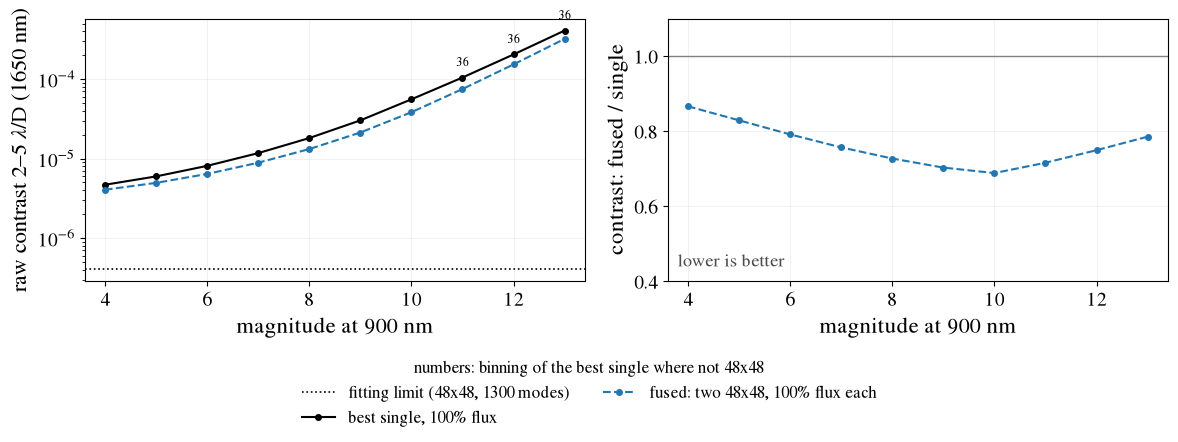

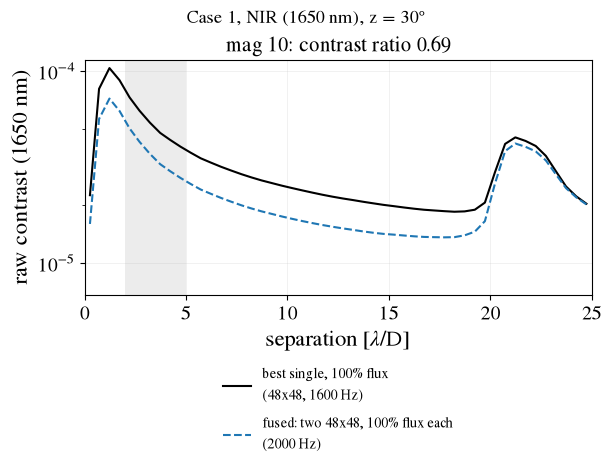

In [ ]:
C1 = {}
for band in BANDS:
    set_band(band)
    r1 = rmod(R1)
    single, double = (sweep(f'c1 {k} rMod{r1:g} {wfs_nm:.0f}', MAGS) for k in ('single', 'double'))
    if single is None or double is None:
        missing(14, f'case 1 {band}', 'not produced', f"c1 {'single' if single is None else 'double'} rMod{r1:g} {wfs_nm:.0f} ({CONTROLLER})",
                'EB sweep (analyse_errorbudget.ipynb, case 1)', 'Study.single / Study.fused')
        continue
    C1[band] = {'single': single, 'double': double}
    fig = case_figure([('best single, 100% flux', single, CFG['single'], EQ, 'o'),
                       ('fused: two 48x48, 100% flux each', double, CFG['case1'], ADD, 'o')], 'best single, 100% flux',
                      f'Case 1, {band_title(band)}, z = {zenith:g}°: 48x48 rMod {r1:g} at {wfs_nm:.0f} nm, second identical sensor',
                      fit=fitting_limit(band), **CASE_KW)
    save(fig, 14, f'case1_{band}_{CONTROLLER}', f'results/multiwfs_cache: c1 single/double rMod{r1:g} {wfs_nm:.0f} ({CONTROLLER})')
    profile_figure(14, f'case1_profiles_{band}_{CONTROLLER}', f'Case 1, {band_title(band)}, z = {zenith:g}°',
                   ('best single, 100% flux', single, rb_single(r1, wfs_nm)),
                   [('fused: two 48x48, 100% flux each', double, rb_fused(lambda mg: [st.sensor(r1, 48, wfs_nm, mg)] * 2), CFG['case1'], ADD)])
missing(14, 'case 1, panel (c) per-term bars', 'partially produced', 'per-term contrast at the lowest-ratio magnitude (not cached)',
        'skipped by decision; would need one budget + PsfEngine.psf_terms per curve at that magnitude', 'Study.single / fused, PsfEngine.psf_terms')

## Slide 15: case 2, temporal woofer-tweeter (48x48 + fast 14x14, 100 modes)

NIR, rMod 0, as in the brief (`CASE2_BANDS`: the VIS sweeps, rMod 2, are cached too).

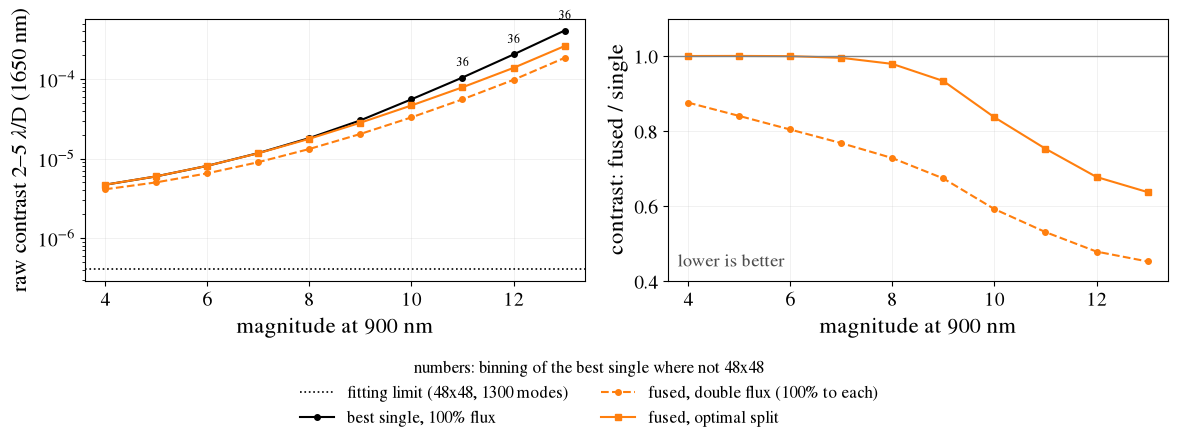

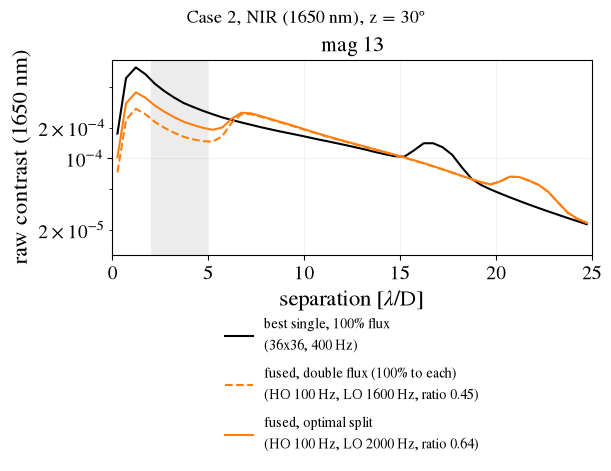

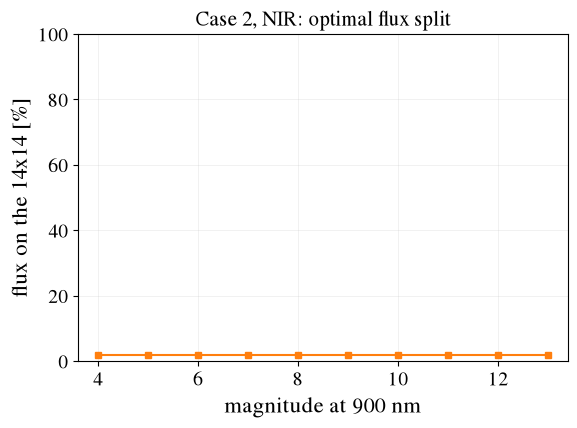

In [ ]:
CASE2_BANDS = ('NIR',)
N_LO, TOL = 100, 0.20
FRAC = [0.02, 0.05, 0.1, 0.15, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]
MAGS2 = np.arange(4.0, 15.01, 1.0)
C2 = {}
for band in BANDS:
    set_band(band)
    tag = f'rMod{rmod(R1):g} {wfs_nm:.0f} N{N_LO}'
    d = {k: sweep(n, MAGS2) for k, n in {'alone': f'c2 alone {tag}', 'double': f'c2 double {tag}',
                                         'split': f'c2 split {tag} tol{TOL:g} {FRAC}'}.items()}
    if any(v is None for v in d.values()):
        if band in CASE2_BANDS:
            missing(15, f'case 2 {band}', 'not produced', f"c2 {[k for k, v in d.items() if v is None]} {tag} ({CONTROLLER})",
                    'EB sweep (analyse_errorbudget.ipynb, case 2)', 'Study.best_single / best_dual / best_split')
        continue
    C2[band] = d
    if band not in CASE2_BANDS:
        continue
    fig = case_figure([('best single, 100% flux', d['alone'], CFG['single'], EQ, 'o'),
                       ('fused, double flux (100% to each)', d['double'], CFG['case2'], ADD, 'o'),
                       ('fused, optimal split', d['split'], CFG['case2'], EQ, 's')], 'best single, 100% flux',
                      f'Case 2, {band_title(band)}, z = {zenith:g}°: 48x48 + 14x14 (first {N_LO} modes), rMod {rmod(R1):g} at {wfs_nm:.0f} nm',
                      fit=fitting_limit(band), **CASE_KW)
    save(fig, 15, f'case2_{band}_{CONTROLLER}', f'results/multiwfs_cache: c2 alone/double/split {tag} ({CONTROLLER})')
    lo2 = lambda share: (lambda mg, row: st.sensor(rmod(R1), 14, wfs_nm, mg, share(row), N=N_LO))
    ho2 = lambda share: (lambda mg, row: st.sensor(rmod(R1), 48, wfs_nm, mg, share(row)))
    profile_figure(15, f'case2_profiles_{band}_{CONTROLLER}', f'Case 2, {band_title(band)}, z = {zenith:g}°',
                   ('best single, 100% flux', d['alone'], rb_single(rmod(R1), wfs_nm)),
                   [('fused, double flux (100% to each)', d['double'], rb_dual(lo2(lambda row: 1.0), ho2(lambda row: 1.0)), CFG['case2'], ADD),
                    ('fused, optimal split', d['split'], rb_dual(lo2(lambda row: row['f_LO']), ho2(lambda row: 1 - row['f_LO'])),
                     CFG['case2'], EQ)], one_panel=True)
    # optimal split per magnitude (saved in the split sweep: f_LO = share of the light on the 14x14)
    fig, ax = plt.subplots(figsize=HALF)
    sp = d['split'][d['split'].index <= CASE_MAG_MAX + 1e-9]
    ax.plot(sp.index, 100 * sp['f_LO'], 's-', color=CFG['case2'])
    ax.set_xlim(XLIM[0], CASE_MAG_MAX + 0.4); ax.set_ylim(0, 100)
    ax.set_xlabel('magnitude at 900 nm'); ax.set_ylabel('flux on the 14x14 [%]')
    ax.set_title(f'Case 2, {band}: optimal flux split')
    fig.tight_layout()
    save(fig, 15, f'case2_split_{band}_{CONTROLLER}', f'results/multiwfs_cache: c2 split {tag} (column f_LO)')
missing(15, 'case 2, panel (c) per-term bars', 'partially produced', 'per-term contrast at the lowest-ratio magnitude (not cached)',
        'skipped by decision', 'Study.best_dual / best_split, PsfEngine.psf_terms')

## Slide 16: case 3, unmodulated sensitivity (50/50 flux)

Single 48x48 rMod 2 vs fusion rMod 2 + rMod 0 (50/50), plus a single unmodulated 48x48 with 100% of the flux. NIR: cached
(`c1 single rMod0 1300`, the NIR single of case 1). VIS: not in the cache; with the leaky controller it is a **quick EB evaluation**
(same call as the cached NIR one, existing 48x48 rMod 0 900 nm products), kept in memory. The quick path is checked against the
cached NIR sweep first.

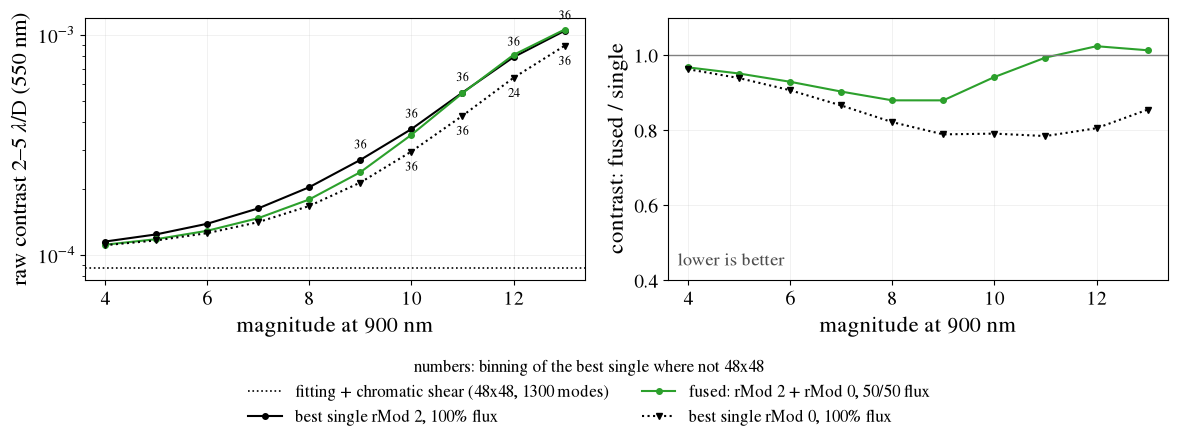

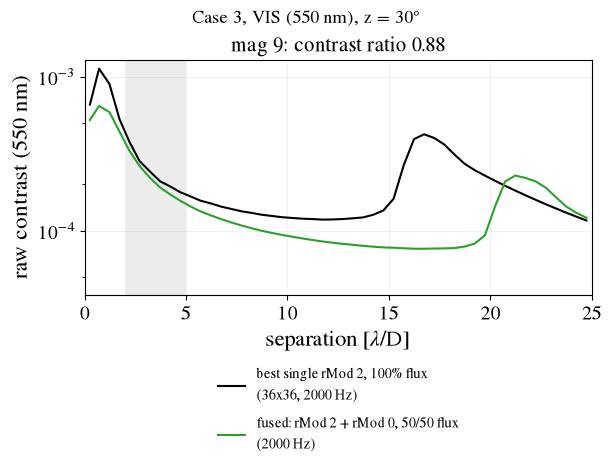

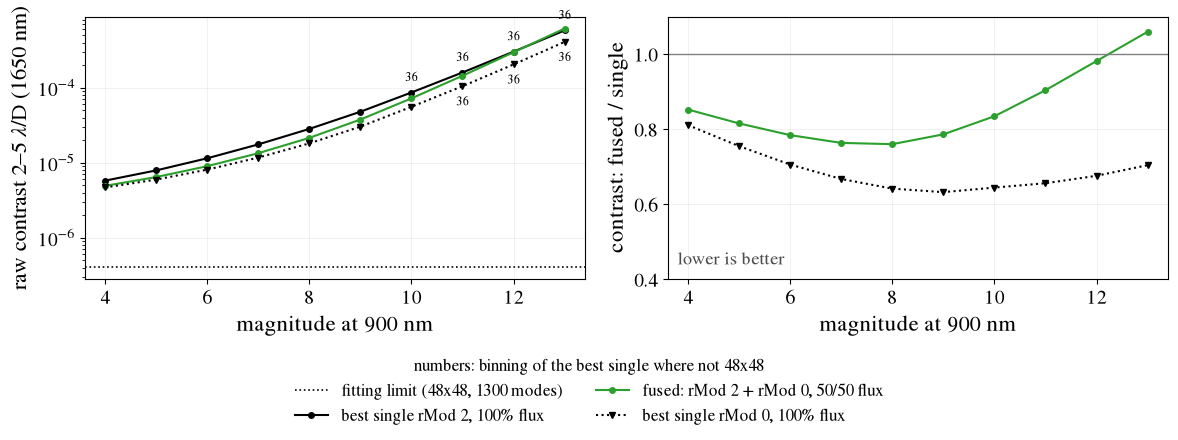

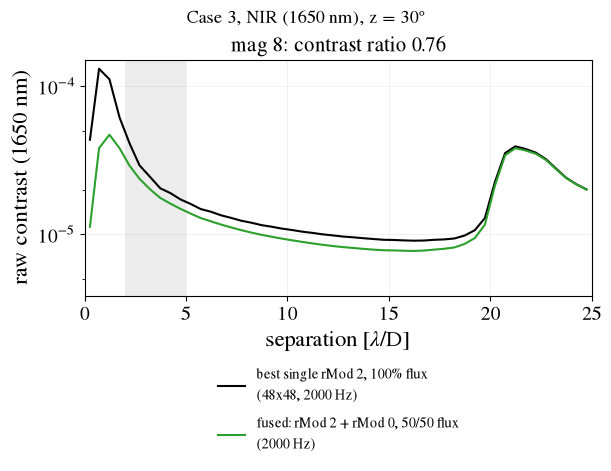

In [ ]:
def quick_sweep(make, mags):
    return pd.DataFrame([{'mag': mg, **st.row(make(mg))} for mg in mags]).set_index('mag')

def unmod_single(band):
    # single unmodulated 48x48, 100% flux: cache, else (leaky only) the same computation in memory -> (sweep, quick?)
    set_band(band)
    cached = sweep(f'c1 single rMod0 {wfs_nm:.0f}', MAGS)
    if cached is not None:
        return cached, False
    if CONTROLLER != 'leaky':
        return None, False
    quick_check()
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        return quick_sweep(lambda mg: st.single(st.sensor(0.0, 48, wfs_nm, mg, 1.0)), MAGS), True

def quick_check(mg=12.0):
    # once, and only if the quick path is needed: it must reproduce the cached NIR sweep (one magnitude: under CRITERION 'contrast'
    # each magnitude is a search over 4 binnings x 14 rates)
    global QUICK_CHECKED
    if globals().get('QUICK_CHECKED'):
        return
    band0 = BAND
    set_band('NIR')
    ref_nir = sweep('c1 single rMod0 1300', MAGS)
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        q = quick_sweep(lambda mg: st.single(st.sensor(0.0, 48, wfs_nm, mg, 1.0)), [mg])
    dev = float(abs(q['contrast'].iloc[0] / ref_nir.loc[mg, 'contrast'] - 1))
    print(f'quick path vs cached NIR rMod 0 single at mag {mg:g}: relative contrast difference {dev:.2e}')
    assert dev < 1e-6
    QUICK_CHECKED = True
    set_band(band0)

C3 = {}
for band in BANDS:
    set_band(band)
    single, fused = sweep(f'c1 single rMod2 {wfs_nm:.0f}', MAGS), sweep(f'c3 split rMod2+0 {wfs_nm:.0f}', MAGS)
    if single is None or fused is None:
        missing(16, f'case 3 {band}', 'not produced', f'c1 single rMod2 / c3 split rMod2+0 {wfs_nm:.0f} ({CONTROLLER})',
                'EB sweep (analyse_errorbudget.ipynb, case 3)', 'Study.single / Study.fused')
        continue
    C3[band] = {'single': single, 'fused': fused}
    unmod, quick = unmod_single(band)
    set_band(band)
    curves = [('best single rMod 2, 100% flux', single, CFG['single'], EQ, 'o'),
              ('fused: rMod 2 + rMod 0, 50/50 flux', fused, CFG['case3'], EQ, 'o')]
    if unmod is not None:
        curves.append(('best single rMod 0, 100% flux', unmod, CFG['single'], ':', 'v'))
    else:
        missing(16, f'case 3 {band}: single rMod 0 baseline', 'partially produced', f'best single rMod 0, 100% flux, {band}, mag 4-14 ({CONTROLLER}, {CRITERION})',
                'EB sweep: Study.single(Study.sensor(0, 48, wfs_nm, mag, 1.0)) per magnitude', 'Study.single')
    fig = case_figure(curves, 'best single rMod 2, 100% flux',
                      f'Case 3, {band_title(band)}, z = {zenith:g}°: two 48x48 at {wfs_nm:.0f} nm, rMod 2 + rMod 0, 50/50 flux',
                      fit=fitting_limit(band), **CASE_KW)
    save(fig, 16, f'case3_{band}_{CONTROLLER}', f'results/multiwfs_cache: c1 single rMod2, c3 split rMod2+0 {wfs_nm:.0f}'
         + ('' if unmod is None else (', rMod 0 single: quick EB (in memory)' if quick else f', c1 single rMod0 {wfs_nm:.0f}')) + f' ({CONTROLLER})',
         quick_eb=f'best single rMod 0 {wfs_nm:.0f} nm, 100% flux, mags 4-14: Study.single ({CRITERION}) on existing products, not cached' if quick else None)
    profile_figure(16, f'case3_profiles_{band}_{CONTROLLER}', f'Case 3, {band_title(band)}, z = {zenith:g}°',
                   ('best single rMod 2, 100% flux', single, rb_single(R1, wfs_nm)),
                   [('fused: rMod 2 + rMod 0, 50/50 flux', fused,
                     rb_fused(lambda mg: [st.sensor(R1, 48, wfs_nm, mg, 0.5), st.sensor(0.0, 48, wfs_nm, mg, 0.5)]), CFG['case3'], EQ)])
missing(16, 'case 3, panel (c) per-term bars', 'partially produced', 'per-term contrast at the lowest-ratio magnitude (not cached)',
        'skipped by decision', 'Study.fused, PsfEngine.psf_terms')

## Slide 17: chromatic shear (case 4a cache)

The cell that made these sweeps was removed from `analyse_errorbudget.ipynb` after commit e3b9efe; the names below are those of that
cell. Left: AO-only contrast (Strehl-optimal rate, no chromatic term) vs the chromatic term alone at z = 30°; right: chromatic term alone
vs WFS wavelength per zenith angle, with the AO-only contrast at mags 6 / 9 / 12. VIS rMod 2, NIR rMod 0.

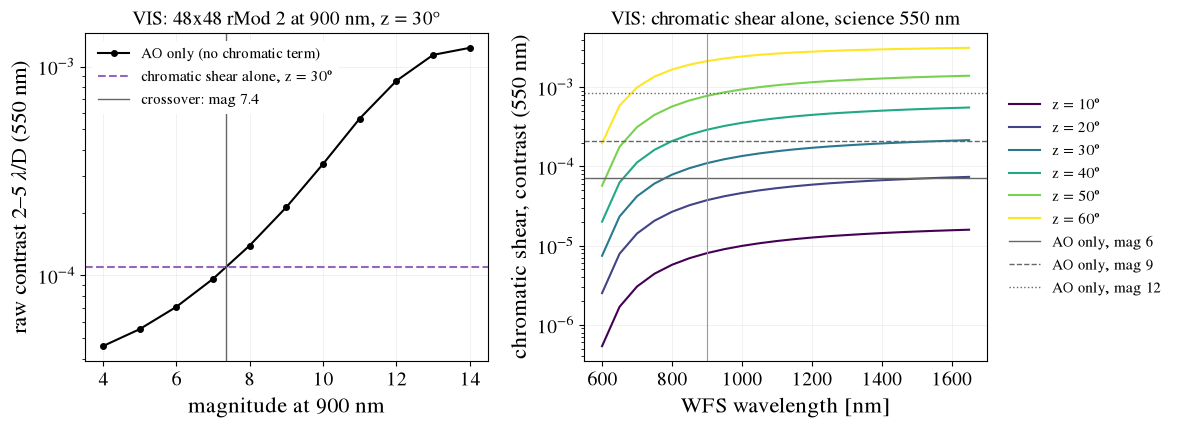

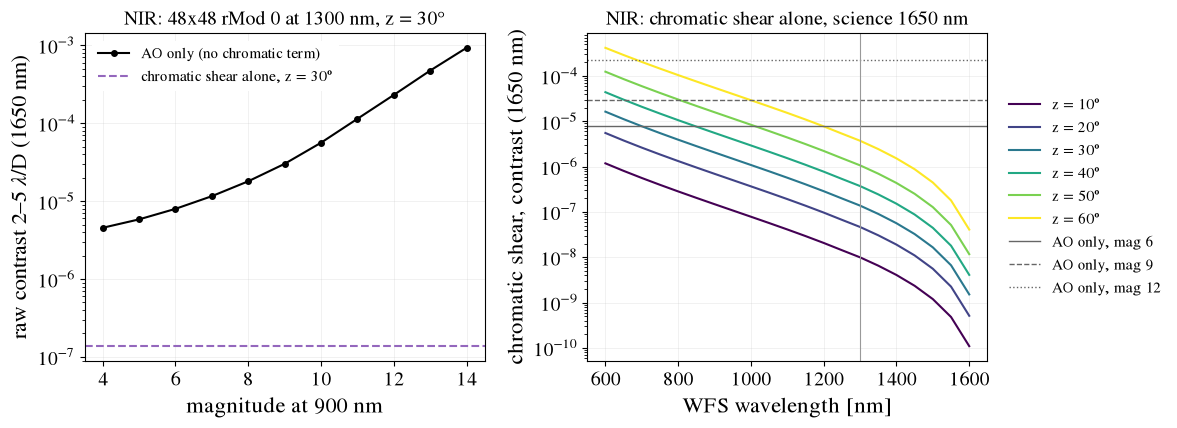

crossover magnitude (AO only = chromatic, z = 30 deg): {'VIS': 7.366170122466575, 'NIR': None}


In [ ]:
WL_W = np.arange(600., 1651., 50.)
ZEN = [10, 20, 30, 40, 50, 60]
MAGS4 = [6.0, 9.0, 12.0]
CROSS = {}
for band in BANDS:
    set_band(band)
    r4 = rmod(R1)
    tag = f'rMod{r4:g} {wfs_nm:.0f}'
    # the c4a sweeps exist only under the Strehl criterion (their cell was removed from analyse_errorbudget.ipynb, never rerun)
    aoc, cc = load(f'c4a aoc {tag}', tuple(MAGS), criterion='strehl'), load(f'c4a chrom {tag}', (tuple(WL_W), tuple(ZEN)), criterion='strehl')
    if aoc is None or cc is None:
        missing(17, f'chromatic shear {band}', 'not produced', f'c4a aoc / chrom {tag} ({CONTROLLER})',
                'EB sweep (cell 19 of analyse_errorbudget.ipynb at e3b9efe)', 'Study.best_single, Study.chromatic_contrast')
        continue
    chrom_now = float(np.asarray(cc[int(zenith)])[np.isclose(WL_W, wfs_nm)][0])      # chromatic alone, WFS of the band, z of the system
    fig, (a, b) = plt.subplots(1, 2, figsize=FULL)
    a.semilogy(MAGS, aoc, 'o-', color=CFG['single'], label=f'AO only (no chromatic term)')
    a.axhline(chrom_now, color=TERM['chrom_shear'], ls='--', label=f'chromatic shear alone, z = {zenith:g}°')
    # crossover: AO-only contrast equal to the chromatic term (log-linear between the two magnitudes that bracket it)
    above = np.asarray(aoc) > chrom_now
    if above.any() and not above.all():
        k = int(np.argmax(above))
        x = MAGS[k - 1] + (np.log(chrom_now) - np.log(aoc[k - 1])) / (np.log(aoc[k]) - np.log(aoc[k - 1]))
        CROSS[band] = x
        a.axvline(x, color='0.4', lw=1, label=f'crossover: mag {x:.1f}')
    else:
        CROSS[band] = None
    a.set_xlabel('magnitude at 900 nm'); a.set_ylabel(f'raw contrast {ZONE_TXT} ({sci_nm:.0f} nm)')
    a.set_title(f'{band}: 48x48 rMod {r4:g} at {wfs_nm:.0f} nm, z = {zenith:g}°', fontsize=14)
    a.legend(fontsize=11, loc='upper left', frameon=True, framealpha=1, edgecolor='none')    # opaque: the crossover line passes behind it
    for j, z in enumerate(ZEN):
        b.semilogy(WL_W, cc[z], '-', color=plt.cm.viridis(j / (len(ZEN) - 1)), label=f'z = {z}°')
    for i, mg in enumerate(MAGS4):
        b.axhline(float(np.interp(mg, MAGS, aoc)), color='0.4', ls=['-', '--', ':'][i], lw=1, label=f'AO only, mag {mg:g}')
    b.axvline(wfs_nm, color='0.6', lw=0.8)
    b.set_xlabel('WFS wavelength [nm]'); b.set_ylabel(f'chromatic shear, contrast ({sci_nm:.0f} nm)')
    b.set_title(f'{band}: chromatic shear alone, science {sci_nm:.0f} nm', fontsize=14)
    b.legend(fontsize=11, loc='center left', bbox_to_anchor=(1.02, 0.5))
    fig.tight_layout()
    save(fig, 17, f'chromatic_{band}_{CONTROLLER}', f'results/multiwfs_cache: c4a aoc/chrom {tag} ({CONTROLLER})')
print('crossover magnitude (AO only = chromatic, z = %g deg):' % zenith, CROSS)

## Slide 18: case 4, chromatic compensation (VIS, z = 30°)

Single 900 nm (all the light of the 900 nm band) vs fusion 750 / 950 nm (25/75 of those photons) vs mode split (first 100 modes from
750 nm only, the rest fused). All curves share one band's photons: flux-equated.

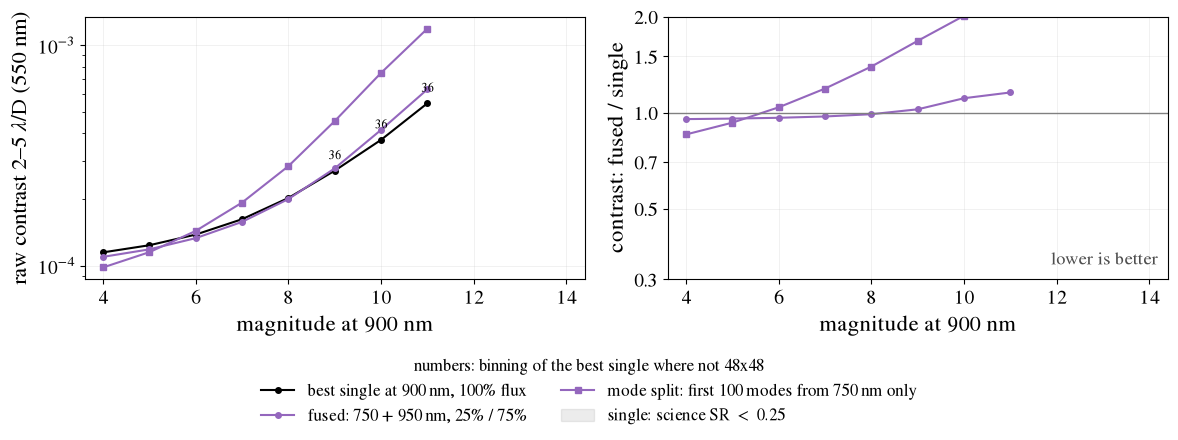

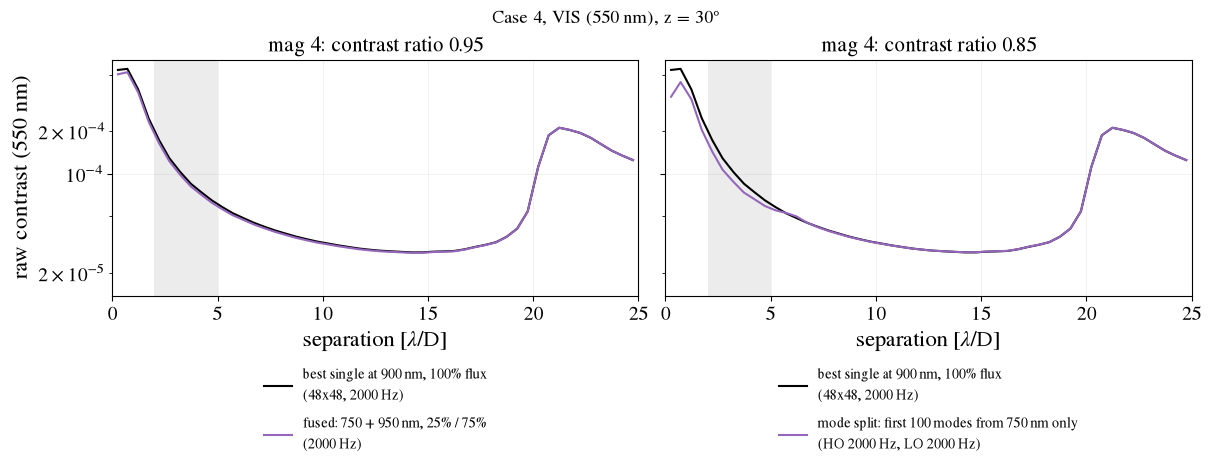

In [ ]:
set_band('VIS')
st.set_band(sci_nm, dataclasses.replace(st.chromatic, zenith_deg=30.0))
MAGSc = MAGS[:-3]
split = 0.25
wvlA, wvlB = 700 + 400 * split / 2, (1800 + 400 * split) / 2
names4 = {'900 nm, all the light': ('best single at 900 nm, 100% flux', CFG['single'], 'o'),
          f'fusion: {wvlA:1.0f} / {wvlB:1.0f} nm, {split*100:1.0f}/{(1-split)*100:1.0f} flux':
              (f'fused: {wvlA:.0f} + {wvlB:.0f} nm, {split:.0%} / {1 - split:.0%}', CFG['case4'], 'o'),
          f'split modes: {split*100:1.0f}/{(1-split)*100:1.0f} flux':
              (f'mode split: first 100 modes from {wvlA:.0f} nm only', CFG['case4'], 's')}
C4 = {k: sweep(f'c4b {k} rMod{R1:g}', MAGSc) for k in names4}
if any(v is None for v in C4.values()):
    missing(18, 'case 4 VIS', 'not produced', f"c4b {[k for k, v in C4.items() if v is None]} rMod2, z = 30 ({CONTROLLER})",
            'EB sweep (analyse_errorbudget.ipynb, case 4)', 'Study.best_rate, budget_fused, combine_stages')
else:
    fig = case_figure([(lab, C4[k], c, EQ, mk) for k, (lab, c, mk) in names4.items()], names4['900 nm, all the light'][0],
                      f'Case 4, {band_title("VIS")}, z = 30°: 48x48 rMod {R1:g}, single 900 nm vs {wvlA:.0f} / {wvlB:.0f} nm')
    save(fig, 18, f'case4_VIS_{CONTROLLER}', f'results/multiwfs_cache: c4b * rMod2 (z = 30) ({CONTROLLER})')
    s4 = lambda wl, mg, sh, f: st.sensor(R1, 48, wl, mg, fs=f) | {'flux': sh * st.flux_of(mg, 900.)}   # as analyse_errorbudget.ipynb

    def rb_fusion4(mg, row):
        f = float(row['fs'])
        return m.budget_fused([s4(wvlA, mg, split, f), s4(wvlB, mg, 1 - split, f)], seeing, f, chromatic=st.chromatic, warn=False, **st.kw)

    def rb_modes4(mg, row):
        f = float(row['fs'])
        pair = [s4(wvlA, mg, split, f), s4(wvlB, mg, 1 - split, f)]
        hi = m.budget_fused(pair, seeing, f, chromatic=st.chromatic, warn=False, **st.kw)
        lo_ = m.budget_fused([{**pair[0], 'N_rec': m.n_modes_ho}], seeing, f, N=100, warn=False, **st.kw)
        return m.combine_stages(lo_, hi, pair[0], {**pair[1], 'wavelength_nm': hi.params['wavelength_nm']}, seeing, st.chromatic)
    k4 = list(names4)
    profile_figure(18, f'case4_profiles_VIS_{CONTROLLER}', f'Case 4, {band_title("VIS")}, z = 30°',
                   (names4[k4[0]][0], C4[k4[0]], rb_single(R1, 900.)),
                   [(names4[k4[1]][0], C4[k4[1]], rb_fusion4, CFG['case4'], EQ), (names4[k4[2]][0], C4[k4[2]], rb_modes4, CFG['case4'], EQ)])
set_band('VIS')
missing(18, 'case 4, panel (c) per-term bars', 'partially produced', 'per-term contrast at the lowest-ratio magnitude, z = 30 (the cached Case_4 PSFs are at z = 50)',
        'skipped by decision', 'budget_fused / combine_stages, PsfEngine.psf_terms')

## Slide 19: summary (fused / single, per advantage)

Left group flux-equated, right group flux-added; bottom row: science SR ratio. Faded dotted: a science SR below 0.25. Magnitudes 5-12
as in the current summary figure.

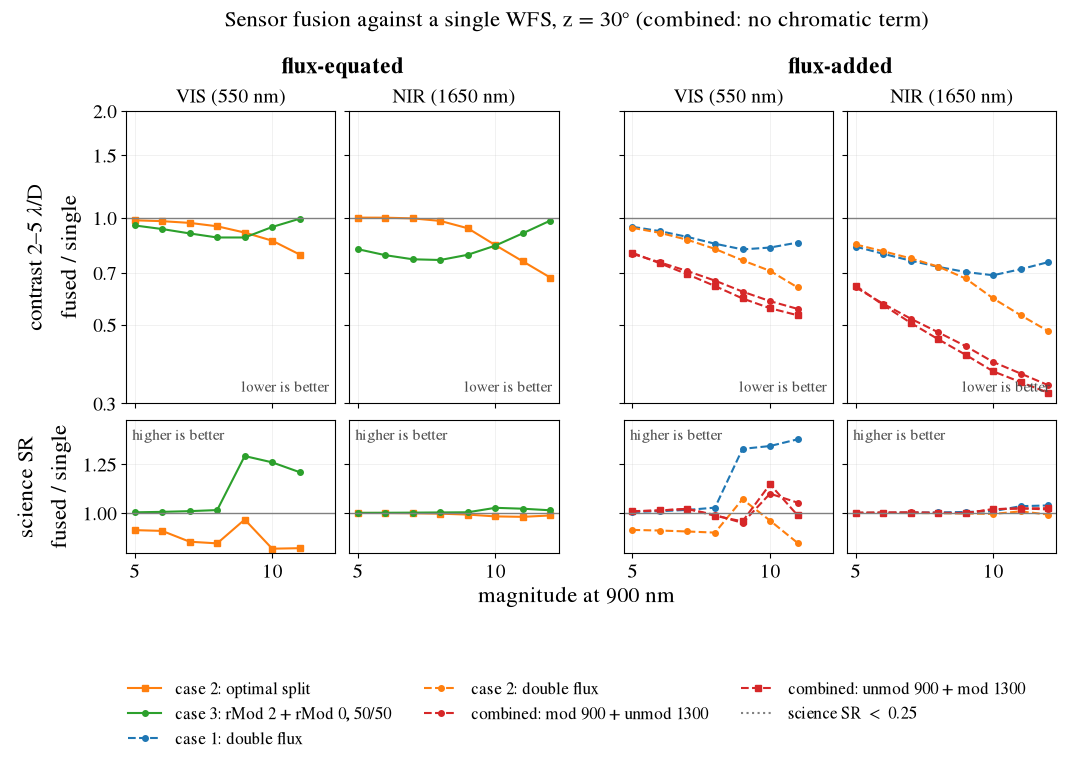

mag                                                         5.0    8.0    12.0
group        configuration                  band quantity                     
flux-added   case 1: double flux            NIR  SR        1.001  1.003  1.038
                                                 contrast  0.829  0.727  0.750
                                            VIS  SR        1.005  1.027  1.444
                                                 contrast  0.943  0.845  0.893
             case 2: double flux            NIR  SR        1.000  0.999  0.992
                                                 contrast  0.841  0.729  0.479
                                            VIS  SR        0.913  0.899  0.921
                                                 contrast  0.936  0.817  0.586
             combined: mod 900 + unmod 1300 NIR  SR        1.000  1.001  1.018
                                                 contrast  0.637  0.476  0.338
                                            VIS  SR        1.009  0.990  0.943
                                                 contrast  0.791  0.665  0.531
             combined: unmod 900 + mod 1300 NIR  SR        1.001  1.000  1.025
                                                 contrast  0.644  0.455  0.321
                                            VIS  SR        1.008  0.985  0.921
                                                 contrast  0.797  0.642  0.516
flux-equated case 2: optimal split          NIR  SR        1.000  0.996  0.987
                                                 contrast  1.001  0.979  0.678
                                            VIS  SR        0.912  0.844  0.869
                                                 contrast  0.983  0.946  0.733
             case 3: rMod 2 + rMod 0, 50/50 NIR  SR        1.000  1.003  1.014
                                                 contrast  0.816  0.760  0.982
                                            VIS  SR        1.003  1.015  1.125
                                                 contrast  0.951  0.880  1.024

In [ ]:
NS_UNMOD = (14, 24, 36, 48)
C5 = {}
for band in BANDS:
    set_band(band)
    d = {'single': sweep(f'c5 single rMod{R1:g} {wfs_nm:.0f}', MAGS),
         'mod 900 + unmod 1300': sweep(f'c5 mod 900 + unmod 1300 rMod{R1:g} n{NS_UNMOD}', MAGS),
         'unmod 900 + mod 1300': sweep(f'c5 unmod 900 + mod 1300 rMod{R1:g} n{NS_UNMOD}', MAGS)}
    if all(v is not None for v in d.values()):
        C5[band] = d
# (group, label, colour, linestyle, marker): (cases dict, reference, fused)
SUM = {('flux-equated', 'case 2: optimal split', CFG['case2'], EQ, 's'): (C2, 'alone', 'split'),
       ('flux-equated', 'case 3: rMod 2 + rMod 0, 50/50', CFG['case3'], EQ, 'o'): (C3, 'single', 'fused'),
       ('flux-added', 'case 1: double flux', CFG['case1'], ADD, 'o'): (C1, 'single', 'double'),
       ('flux-added', 'case 2: double flux', CFG['case2'], ADD, 'o'): (C2, 'alone', 'double'),
       ('flux-added', 'combined: mod 900 + unmod 1300', CFG['combined'], ADD, 'o'): (C5, 'single', 'mod 900 + unmod 1300'),
       ('flux-added', 'combined: unmod 900 + mod 1300', CFG['combined'], ADD, 's'): (C5, 'single', 'unmod 900 + mod 1300')}
MAG_SUM = (5.0, 12.0)
fig = plt.figure(figsize=(12, 7.5))
gs = fig.add_gridspec(2, 5, height_ratios=(2.2, 1), width_ratios=(1, 1, 0.18, 1, 1), hspace=0.08, wspace=0.08)
cols = {('flux-equated', 'VIS'): 0, ('flux-equated', 'NIR'): 1, ('flux-added', 'VIS'): 3, ('flux-added', 'NIR'): 4}
ax = {(g, b, r): fig.add_subplot(gs[r, c]) for (g, b), c in cols.items() for r in (0, 1)}
rows, absent = [], []
for (grp, lab, col, ls, mk), (Cx, ref, fu) in SUM.items():
    for band in BANDS:
        if band not in Cx:
            absent.append(f'{lab} {band}')
            continue
        for r, q in ((0, 'contrast'), (1, 'SR')):
            g = pl.fusion_gain(Cx[band][ref], Cx[band][fu], st.sr_min, col=q)
            g = g[(g.index >= MAG_SUM[0]) & (g.index <= MAG_SUM[1])]
            a = ax[grp, band, r]
            a.plot(g.index, g['ratio'].where(g['ok']), ls=ls, color=col, marker=mk, ms=4, label=lab)
            a.plot(g.index, g['ratio'].where(~g['ok']), ':', color=col, lw=1, alpha=0.5)
            for mg in (5.0, 8.0, 12.0):
                rows.append(dict(group=grp, configuration=lab, band=band, quantity=q, mag=mg, ratio=g['ratio'].get(mg, np.nan),
                                 SR_ok=bool(g['ok'].get(mg, False))))
for (g, b, r), a in ax.items():
    a.axhline(1.0, color='gray', lw=1)
    a.set_xlim(MAG_SUM[0] - 0.3, MAG_SUM[1] + 0.3)
    if r == 0:
        a.set_yscale('log'); a.set_ylim(*RATIO_YLIM)
        a.yaxis.set_major_locator(FixedLocator(RATIO_TICKS)); a.yaxis.set_minor_locator(NullLocator())
        a.yaxis.set_major_formatter(ScalarFormatter())
        a.set_title(band_title(b), fontsize=14)
        a.tick_params(labelbottom=False)
        a.text(0.97, 0.04, 'lower is better', transform=a.transAxes, ha='right', fontsize=11, color='0.3')
    else:
        a.text(0.03, 0.94, 'higher is better', transform=a.transAxes, ha='left', va='top', fontsize=11, color='0.3')
    if (g, b) != ('flux-equated', 'VIS'):
        a.tick_params(labelleft=False)
lo = min(a.get_ylim()[0] for (g, b, r), a in ax.items() if r == 1)
hi = max(a.get_ylim()[1] for (g, b, r), a in ax.items() if r == 1)
for (g, b, r), a in ax.items():
    if r == 1:
        a.set_ylim(lo, hi)
ax['flux-equated', 'VIS', 0].set_ylabel(f'contrast {ZONE_TXT}\nfused / single')
ax['flux-equated', 'VIS', 1].set_ylabel('science SR\nfused / single')
h, l = [], []
for g in ('flux-equated', 'flux-added'):
    hh, ll = ax[g, 'VIS', 0].get_legend_handles_labels()
    h += hh; l += ll
h.append(Line2D([], [], color='gray', ls=':')); l.append(f'science SR $<$ {st.sr_min:g}')
fig.legend(h, l, loc='lower center', ncol=3, fontsize=12, frameon=False, bbox_to_anchor=(0.5, -0.01))
fig.subplots_adjust(bottom=0.27, top=0.86)
for g, (x0, x1) in {'flux-equated': (0, 1), 'flux-added': (3, 4)}.items():
    p0, p1 = ax[g, 'VIS', 0].get_position(), ax[g, 'NIR', 0].get_position()
    fig.text((p0.x0 + p1.x1) / 2, 0.91, g, ha='center', fontsize=16, weight='bold')
fig.text(0.5, 0.205, 'magnitude at 900 nm', ha='center', fontsize=16)
fig.suptitle(f'Sensor fusion against a single WFS, z = {zenith:g}° (combined: no chromatic term)', y=0.995)
save(fig, 19, f'summary_{CONTROLLER}', f'results/multiwfs_cache: sweeps of cases 1, 2, 3 and 5 ({CONTROLLER}); aoeb.plotting.fusion_gain')
TAB19 = pd.DataFrame(rows).pivot_table(index=['group', 'configuration', 'band', 'quantity'], columns='mag', values='ratio')
TAB19.round(3).to_csv(op.join(OUT, f'slide19_ratios_{CONTROLLER}.csv'))
if absent:
    missing(19, 'summary', 'partially produced', ', '.join(absent) + f' ({CONTROLLER})', 'the EB sweeps of those cases', 'see cases 1-5')
TAB19.round(3)

## Slide 21: Kalman filter block diagram

From `specula/processing_objects/kalman_filter.py` and the `kalman` / `kpred` / `dm` objects of `aoeb/e2e/ristretto_main.yml`. The
filter takes the two **modal** reconstructions (`pyr_modes_vis.out_modes`, `pyr_modes_nir.out_modes`), not the slopes. The sensor-bias
states exist in the code but are disabled in every run of the talk (`out_bias` commented in the yml): drawn dashed.

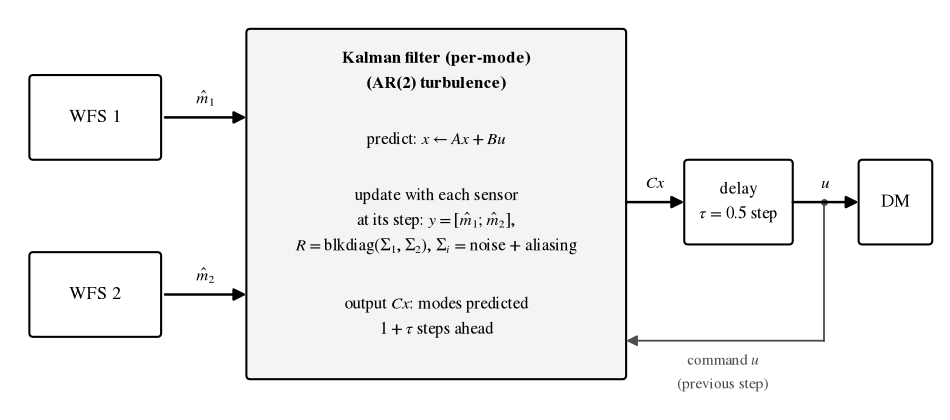

In [ ]:
fig, ax = plt.subplots(figsize=(12, 5.2))
ax.set_xlim(0, 12); ax.set_ylim(0, 5.2); ax.axis('off'); ax.grid(False)

def box(x, y, w, h, text, fc='white', ec='k', ls='-', fs=12):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle='round,pad=0.05', fc=fc, ec=ec, ls=ls, lw=1.5))
    ax.text(x + w / 2, y + h / 2, text, ha='center', va='center', fontsize=fs, color=ec if ec != 'k' else 'k')

def arrow(x0, y0, x1, y1, text=None, dy=0.12, color='k', ls='-'):
    ax.annotate('', (x1, y1), (x0, y0), arrowprops=dict(arrowstyle='-|>', lw=1.8, color=color, ls=ls, mutation_scale=18, shrinkA=0, shrinkB=0))
    if text:
        ax.text((x0 + x1) / 2, max(y0, y1) + dy, text, ha='center', va='bottom', fontsize=12)

# two generic inputs
box(0.3, 3.3, 1.6, 1.0, 'WFS 1', fs=13)
box(0.3, 1.0, 1.6, 1.0, 'WFS 2', fs=13)
arrow(2.0, 3.8, 3.05, 3.8, '$\\hat m_1$')
arrow(2.0, 1.5, 3.05, 1.5, '$\\hat m_2$')
# Kalman filter: all the text inside the box
box(3.1, 0.45, 4.8, 4.45, '', fc='#f4f4f4')
cx = 3.1 + 4.8 / 2
ax.text(cx, 4.4, 'Kalman filter (per-mode)\n(AR(2) turbulence)', ha='center', va='center', fontsize=12, weight='bold')
ax.text(cx, 3.5, 'predict: $x \\leftarrow A x + B u$', ha='center', va='center', fontsize=12)
ax.text(cx, 2.45, 'update with each sensor\nat its step: $y = [\\hat m_1; \\hat m_2]$,\n$R = \\mathrm{blkdiag}(\\Sigma_1, \\Sigma_2)$, '
        '$\\Sigma_i$ = noise + aliasing', ha='center', va='center', fontsize=12)
ax.text(cx, 1.2, 'output $C x$: modes predicted\n$1 + \\tau$ steps ahead', ha='center', va='center', fontsize=12)
# box(5.6, 0.05, 3.4, 0.45, 'sensor-bias states: in the code, off in these runs', ec='0.5', ls='--', fs=10)
# a pure delay, then the DM
YO = 2.7
box(8.75, 2.2, 1.3, 1.0, 'delay\n$\\tau$ = 0.5 step', fs=12)
box(11.0, 2.2, 0.85, 1.0, 'DM', fs=13)
arrow(7.95, YO, 8.7, YO, '$C x$')
arrow(10.1, YO, 10.95, YO, '$u$')
# delayed command back to the filter
ax.plot([10.5, 10.5], [YO, 0.9], color='0.3', lw=1.3)
ax.plot([10.5], [YO], 'o', color='0.3', ms=4)
ax.annotate('', (7.95, 0.9), (10.5, 0.9), arrowprops=dict(arrowstyle='-|>', lw=1.3, color='0.3', mutation_scale=16, shrinkA=0, shrinkB=0))
ax.text(9.2, 0.78, 'command $u$\n(previous step)', ha='center', va='top', fontsize=11, color='0.3')
save(fig, 21, 'kalman_block_diagram', 'specula/processing_objects/kalman_filter.py; aoeb/e2e/ristretto_main.yml (kalman, kpred, dm)')

## Slide 22: increased dynamic range (E2E seeing scan, mag 7, achromatic)

`results/WFSW/sweep_seeing_20261110` (`sweep_seeing.py`): 10 realizations of 2 s per case and seeing, all 48x48, 1300 modes, 2 kHz,
900 nm, Kalman filter. Per-step science SR at 550 nm of every run (`sr_vis.fits` in its run folder, `tn` column of `results.csv`):
mean over the 10 runs (line) ± std (shaded). Lost loops are included, as in `table.md`. The averages of `results.csv` are taken
after `START_TIME` (0.5 s, not marked on the figure); the notebook checks that the series reproduce them. 1.3" is in the scan but not shown.

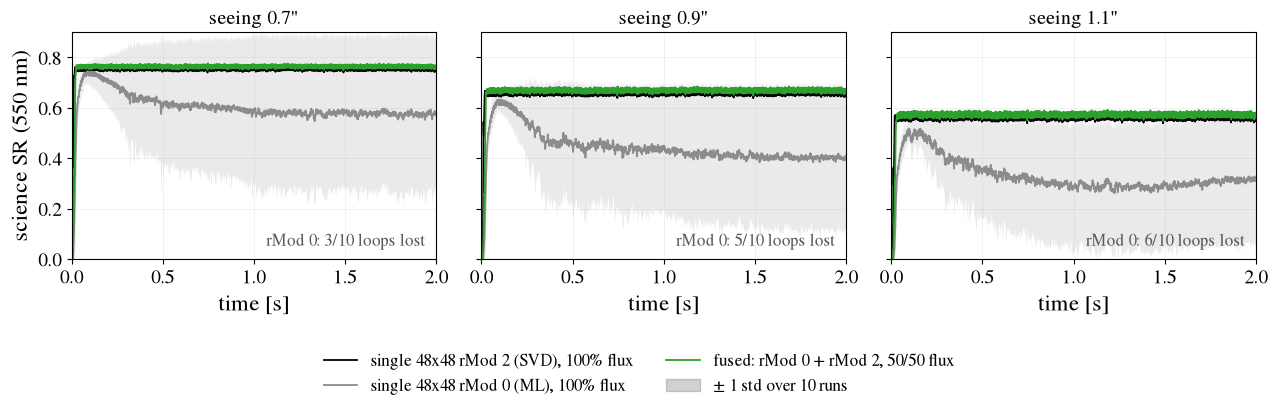

In [ ]:
from astropy.io import fits
SEE22 = (0.7, 0.9, 1.1)
STY22 = {'single_r2': ('single 48x48 rMod 2 (SVD), 100% flux', CFG['single'], EQ),
         'single_r0': ('single 48x48 rMod 0 (ML), 100% flux', '0.55', EQ),
         'dual': ('fused: rMod 0 + rMod 2, 50/50 flux', CFG['case3'], EQ)}
rows22, st22 = ssee.read_rows(), ssee.stats()

def sr_series(r):
    path = op.join(ssee.OUT, f"{r['case']}_s{r['seeing']:g}", 'runs', f"k{r['realization']}", r['tn'], 'sr_vis.fits')
    with fits.open(path) as h:
        y, t = np.asarray(h[0].data, float), np.asarray(h[1].data, float) * 1e-9
    m = float(y[t >= sc_start - 1e-9].mean())
    assert abs(m - r['sr_vis']) < 1e-4, (path, m, r['sr_vis'])        # same runs as results.csv / table.md
    return t, y

import sweep_contrast as _sc
sc_start = _sc.START_TIME
fig, axs = plt.subplots(1, len(SEE22), figsize=(13, 4.2), sharey=True)
for ax, see in zip(axs, SEE22):
    for case, (lab, col, ls) in STY22.items():
        rs = [r for r in rows22 if r['case'] == case and r['seeing'] == see]
        series = [sr_series(r) for r in rs]
        t = series[0][0]
        Y = np.stack([y for _, y in series])
        mu, sd = Y.mean(0), Y.std(0, ddof=1)
        ax.fill_between(t, np.clip(mu - sd, 0, None), mu + sd, color=col, alpha=0.18, lw=0)
        ax.plot(t, mu, color=col, ls=ls, lw=1.3, label=lab)
    n_lost = st22['single_r0'][see]['lost']
    if n_lost:
        ax.text(0.97, 0.04, f"rMod 0: {n_lost}/{st22['single_r0'][see]['n']} loops lost", transform=ax.transAxes, ha='right', va='bottom',
                fontsize=12, color='0.35')
    ax.set_title(f'seeing {see:g}"', fontsize=14)
    ax.set_xlabel('time [s]'); ax.set_xlim(0, ssee.TOTAL_TIME); ax.set_ylim(0, 0.9)
axs[0].set_ylabel('science SR (550 nm)')
h, l = axs[0].get_legend_handles_labels()
h.append(Patch(color='k', alpha=0.18)); l.append(f'± 1 std over {ssee.N_REAL} runs')
fig.tight_layout(rect=(0, 0.17, 1, 1))
fig.legend(h, l, loc='lower center', ncol=2, fontsize=12)
save(fig, 22, 'dynamic_range_seeing', 'results/WFSW/sweep_seeing_20261110: sr_vis.fits of every run listed in results.csv (sweep_seeing.read_rows / stats)')

## Slide 23: E2E contrast profiles (best single vs best fusion per panel)

Selection of `final_sweep_results.plot_profiles` (lowest replay-mean 2-5 λ/D contrast among the single stages rMod 0 / 2 and among
the fusions), replay mean ± std. Grey lines: perfect-coronagraph references. All curves use the Kalman filter; the table below lists
the exact configuration of each curve.

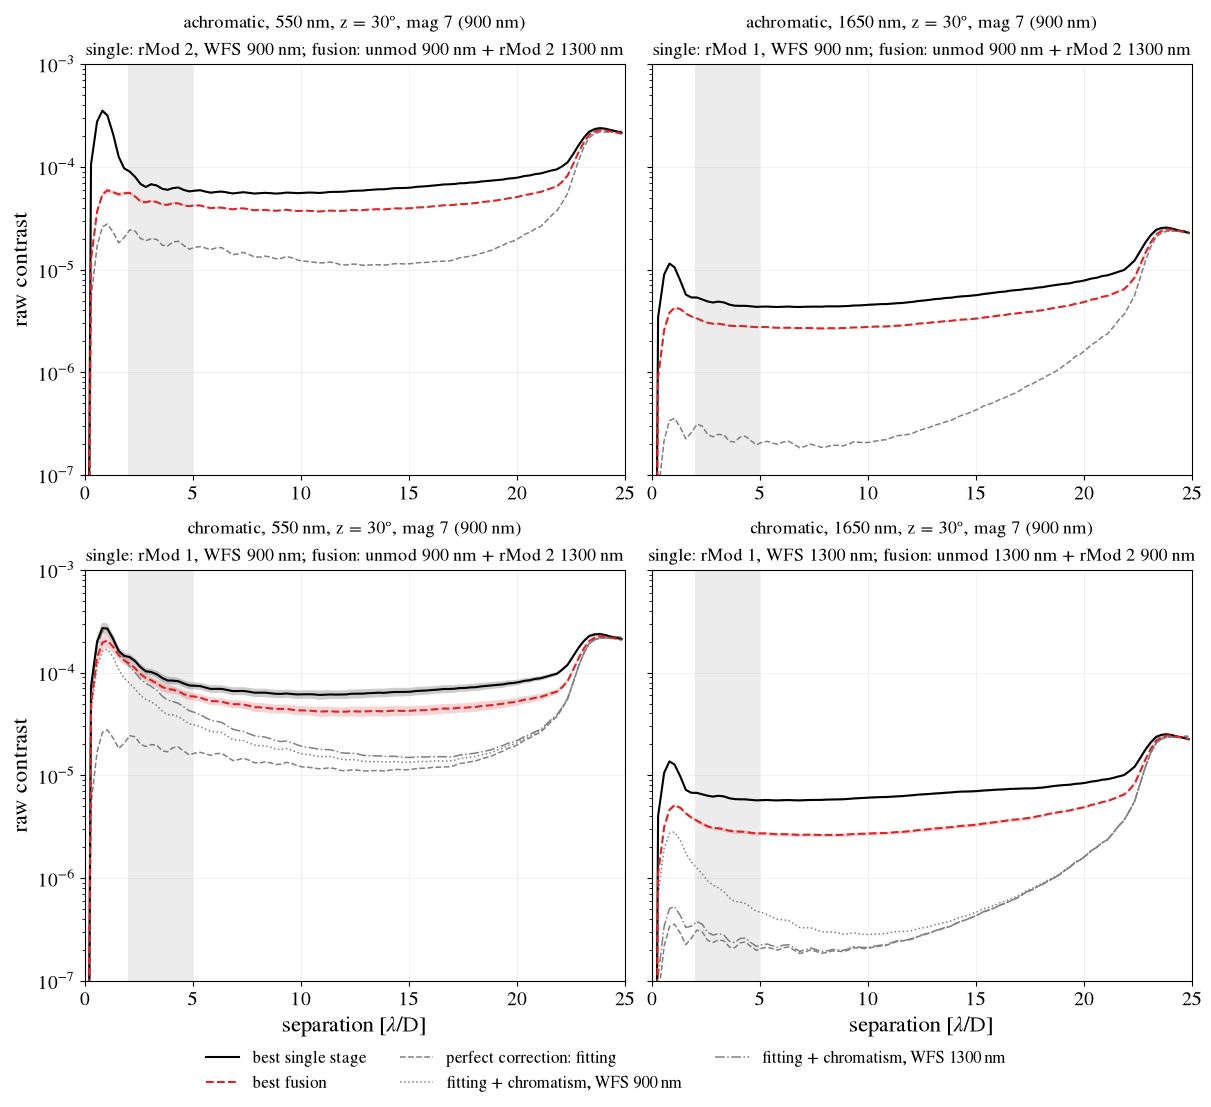

,panel,curve,label,case,configuration,controller,data,contrast_2_5
0,"achromatic, 550 nm",single,"single, rMod 2",single_wfs900_achrom_r2,"rMod 2, 48x48, 1300 modes, 2000 Hz, KF svd",Kalman filter,10/10 replays,0.000066
1,"achromatic, 550 nm",fusion,fusion: unmod 900 nm + rMod 2 1300 nm,dual_unmod900_achrom,unmod 900 nm 100% band 48x48 1300 modes 2000 H...,Kalman filter,10/10 replays,0.000046
2,"achromatic, 1650 nm",single,"single, rMod 1",single_wfs900_achrom_r1,"rMod 1, 48x48, 1300 modes, 2000 Hz, KF svd",Kalman filter,10/10 replays,0.000005
3,"achromatic, 1650 nm",fusion,fusion: unmod 900 nm + rMod 2 1300 nm,dual_unmod900_achrom,unmod 900 nm 100% band 48x48 1300 modes 2000 H...,Kalman filter,10/10 replays,0.000003
4,"chromatic, 550 nm",single,"single, rMod 1",single_wfs900_chrom_r1,"rMod 1, 48x48, 1300 modes, 2000 Hz, KF svd",Kalman filter,10/10 replays,0.000098
5,"chromatic, 550 nm",fusion,fusion: unmod 900 nm + rMod 2 1300 nm,dual_unmod900_chrom,unmod 900 nm 100% band 48x48 1300 modes 2000 H...,Kalman filter,10/10 replays,0.000081
6,"chromatic, 1650 nm",single,"single, rMod 1",single_wfs1300_chrom_r1,"rMod 1, 48x48, 1300 modes, 2000 Hz, KF svd",Kalman filter,10/10 replays,0.000006
7,"chromatic, 1650 nm",fusion,fusion: unmod 1300 nm + rMod 2 900 nm,dual_unmod1300_chrom,unmod 1300 nm 100% band 48x48 1300 modes 2000 ...,Kalman filter,10/10 replays,0.000003


In [ ]:
MAG23 = 7.0
refs = {c: fr.load_perfect_coro(c) for c in ('achrom', 'vis', 'nir')}
fig, axs = plt.subplots(2, 2, figsize=(12, 11), sharex=True, sharey=True, layout='constrained')
cfg23, notes, leg23 = [], set(), {}       # leg23: one common legend (label -> handle)
for (chrom, band), curves in fr.main_panels().items():
    ax = axs[int(chrom), 0 if band == 'vis' else 1]
    bi = 1 if band == 'vis' else 2
    rad = refs['achrom'][0]
    sel = rad <= 25
    ax.axvspan(*ZONE, color='gray', alpha=0.15, lw=0)
    bounds = [('achrom', 'perfect correction: fitting', '--')] + ([('vis', 'fitting + chromatism, WFS 900 nm', ':'),
                                                                   ('nir', 'fitting + chromatism, WFS 1300 nm', '-.')] if chrom else [])
    for c, lab, ls in bounds:
        leg23[lab], = ax.plot(rad[sel], refs[c][bi][sel], color='0.5', lw=1.1, ls=ls)
    won = {}
    for group, col, ls in (('single', CFG['single'], EQ), ('fusion', CFG['combined'], ADD)):
        best = fr._best_case([(lab, c) for e, lab, c in curves if (e.startswith('r') if group == 'single' else e in ('fusion', 'swapped'))],
                             MAG23, band, notes)
        if best is None:
            continue
        lab, case = best
        r, mean, sd, how = fr.profile(case, MAG23, band)
        k = r <= 25
        won[group] = lab
        leg23[f'best {group} stage' if group == 'single' else 'best fusion'], = ax.semilogy(r[k], mean[k], color=col, ls=ls, lw=1.5)
        if sd is not None:
            ax.fill_between(r[k], np.maximum(mean[k] - sd[k], 1e-12), mean[k] + sd[k], color=col, alpha=0.2, lw=0)
        sel_cfg = fr.selected(case).get(MAG23, {})
        cfg23.append(dict(panel=f"{'chromatic' if chrom else 'achromatic'}, {fr.WL[band]}", curve=group, label=lab, case=case,
                          configuration=sel_cfg.get('config', 'replay of the mag 7 config'), controller='Kalman filter', data=how,
                          contrast_2_5=float(np.mean(mean[(r >= ZONE[0]) & (r <= ZONE[1])]))))
    w_single = 1300 if (band == 'nir' and chrom) else 900             # WFS of the single stage (fr._title)
    who = '; '.join(([f"single: {won['single'].replace('single, ', '')}, WFS {w_single} nm"] if 'single' in won else [])
                    + ([f"fusion: {won['fusion'].split(': ', 1)[-1]}"] if 'fusion' in won else []))
    ax.set_title(f"{'chromatic' if chrom else 'achromatic'}, {fr.WL[band]}, z = {zenith:g}°, mag {MAG23:g} (900 nm)\n{who}", fontsize=13)
    ax.set_ylim(*fr.PROFILE_YLIM); ax.set_xlim(0, 25)
    if band == 'vis':
        ax.set_ylabel('raw contrast')
    if chrom:
        ax.set_xlabel('separation [$\\lambda$/D]')
    ax.tick_params(labelbottom=True)
order = [k for k in ('best single stage', 'best fusion') if k in leg23] + [k for k in leg23 if not k.startswith('best')]
fig.legend([leg23[k] for k in order], order, loc='outside lower center', ncol=3, fontsize=12, frameon=False)
save(fig, 23, f'e2e_profiles_mag{MAG23:g}', 'results/WFSW/sweep_final_20261108 (replays; final_sweep_results.profile / _best_case / load_perfect_coro)')
if notes:
    print('selection notes:', sorted(notes))
CFG23 = pd.DataFrame(cfg23)
CFG23

## README.md and MISSING_DATA.md

In [ ]:
missing(24, 'EB vs E2E validation', 'not produced', 'EB runs for the E2E configurations of slide 23 (Kalman controller, chromatic, z = 30, selected rates and sizes)',
        'skipped by decision: no EB controller is a Kalman filter; the closest EB case (combined, case 5) has no chromatic term and optimised rates',
        'ErrorBudgetMachine.budget_dual / budget_fused with the E2E rates and sizes, PsfEngine.psf_terms')
missing('28-39', 'backup slides', 'not produced', '-', 'skipped by decision: several were made from other data sets', '-')

commit = subprocess.run(['git', 'rev-parse', '--short', 'HEAD'], capture_output=True, text=True).stdout.strip()
dirty = subprocess.run(['git', 'status', '--porcelain', '--', '.'], capture_output=True, text=True).stdout.strip()
with open(op.join(OUT, 'README.md'), 'w') as f:
    f.write(f'# WFS Workshop 2026 talk figures ({CONTROLLER})\n\nNotebook: config/wfs_talk_figures.ipynb, commit {commit}'
            f"{' (uncommitted changes in config/)' if dirty else ''}. EB controller: {CONTROLLER}; z = {zenith:g} deg, seeing {seeing}\" "
            f'along the line of sight. EB selection criterion: {CRITERION}'
            + (" (every single-sensor reference is the best binning 48/36/24/14 and frame rate, every fusion at its best frame rate, ranked as "
               "the e2e runs: 2-5 lambda/D contrast among SR >= 10 %, then SR; slide 17 uses the older Strehl-criterion c4a sweeps)" if CRITERION == 'contrast' else '')
            + '.\n\n| slide | file (.pdf, .png) | data and code | quick EB evaluation |\n| --- | --- | --- | --- |\n')
    for r in README:
        f.write(f"| {r['slide']} | {r['file']} | {r['sources']} | {r['quick_eb'] or '-'} |\n")
    f.write(f'\nslide19_ratios_{CONTROLLER}.csv: contrast and SR ratios (fused / single) at mags 5, 8, 12.\n')
with open(op.join(OUT, 'MISSING_DATA.md'), 'w') as f:
    f.write(f'# Missing data ({CONTROLLER})\n')
    for e in MISSING:
        f.write(f"\n### Slide {e['slide']} – {e['figure']}\n- Status: {e['status']}\n- Missing: {e['what']}\n- Needed to produce it: {e['needed']}\n"
                f"- Existing code that would generate it: {e['code']}\n- Discrepancies found: {e['disc']}\n")
print(f"{len(README)} figures, {len(MISSING)} missing-data entries -> {OUT}")
pd.DataFrame(MISSING)[['slide', 'figure', 'status', 'what']]

26 figures, 6 missing-data entries -> /raid1/mmenessini/git/SPECULA/config/figures/leaky


,slide,figure,status,what
0,14,"case 1, panel (c) per-term bars",partially produced,per-term contrast at the lowest-ratio magnitud...
1,15,"case 2, panel (c) per-term bars",partially produced,per-term contrast at the lowest-ratio magnitud...
2,16,"case 3, panel (c) per-term bars",partially produced,per-term contrast at the lowest-ratio magnitud...
3,18,"case 4, panel (c) per-term bars",partially produced,per-term contrast at the lowest-ratio magnitud...
4,24,EB vs E2E validation,not produced,EB runs for the E2E configurations of slide 23...
5,28-39,backup slides,not produced,-
